# ***World-model evaluation with quality and treatment diagnostics***

Evaluation asks whether a saved model predicts unseen measurements better than a simple reference, and whether that advantage survives longer forecasting. For example, matching the next five-second reading is easier when the signal hardly changes; a useful planning model must also be assessed after several minutes without new observations.

Models are loaded with their frozen transformations and checked against artifact hashes, ordered targets, sampling interval and observation rule. Evaluation never refits scaling or trains replacement models. Checkpoint reproduction uses the exact validation starts saved during training. A separate, broader time-stratified cohort assesses performance across the episode. A dose/quality-event audit deliberately inspects unusual periods and remains separate from the overall score.

All predicted channels are reported, with a separate group for pH, COD, BOD, DO and water ammonia. Priority reporting does not introduce hidden loss weights. Recorded future actions condition historical replay; they do not demonstrate how a newly chosen policy would perform.

The reference repeats the latest observation where a target has input history and uses a training mean for output-only targets. Thus the combined reference is a hybrid. The reduced physical model is compared only on oxygen and water temperature at its saved one-step duration. It is excluded from longer recursive comparisons pending a defensible light/background model.

Quality flags identify spike candidates, long identical runs and screening-range issues, without deleting readings. For example, a model can perform well during stable periods but miss a short dose response; the separate event report makes that visible. These flags are retrospective descriptive labels and never become model inputs.

Non-finite forecasts invalidate rankings rather than silently removing failed channels. Negative concentrations and out-of-range pH are counted before any clipping. A zero training variance makes normalization unavailable and is reported separately from a failed prediction.

Probabilistic models receive per-channel likelihood, prediction-interval coverage and interval-width reports. For example, a nominal 90% interval containing nearly every observation may simply be too wide. Ensemble likelihood and quantiles use the predictive mixture. Longer-horizon uncertainty calibration is not inferred from one-step intervals.

Five-second point targets and minute averages describe different observations. Recipes can be compared only with compatible targets, shared real-time forecast durations, matching source data and declared training budgets. Proxy biomass/BOD/TSS scores remain agreement with supplied columns, not independent biological or compliance evidence. The final test stays reserved until the recipe and reporting plan are frozen.

Trajectory plots use a separate contiguous clip from the middle of the longest eligible segment, chosen without looking at model errors. This preserves a readable time trace while the overall scores use widely spread assessment starts. Trace anchors are exported separately.

Training can deliberately enrich rare logged treatment examples. This policy is read from metadata, while the primary evaluation cohort remains a separate temporal sample. Training-time treatment diagnostics are supplementary evidence and do not replace the representative validation score. Output-dependency checks are descriptive; the full-target average must not be interpreted as independent evidence for every channel.

## ***Import***

Rerunning this section refreshes the local experiment helpers from this project, including their shared protocol. This prevents an existing kernel from retaining older helper code after notebook updates. Run the notebook from the top after an update.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from io import BytesIO
import importlib
import json
import sys
import time
import traceback

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_ROOT_OVERRIDE = None
def locate_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        return Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'dev' / 'AGENTS.md').is_file():
            return candidate
    raise FileNotFoundError('Set PROJECT_ROOT_OVERRIDE to the project directory.')

PROJECT_ROOT = locate_root()
WORLD_MODEL_DIR = PROJECT_ROOT / 'dev' / 'world_model'
sys.path.insert(0, str(WORLD_MODEL_DIR))
DATASET_EDA_DIR = PROJECT_ROOT / 'dev' / 'dataset_eda'
sys.path.insert(0, str(DATASET_EDA_DIR))
importlib.invalidate_caches()

def refresh_local_helper(name):
    expected = (WORLD_MODEL_DIR / f'{name}.py').resolve()
    cached = sys.modules.get(name)
    if cached is not None and Path(getattr(cached, '__file__', '') or '').resolve() != expected:
        del sys.modules[name]
        cached = None
    module = importlib.reload(cached) if cached is not None else importlib.import_module(name)
    if Path(module.__file__).resolve() != expected:
        raise ImportError(f'{name} was loaded from {module.__file__}; expected {expected}.')
    return module

wp = refresh_local_helper('world_model_protocol')
wm = refresh_local_helper('world_models')
print('World-model modules loaded from:', WORLD_MODEL_DIR)
display(wm.availability())
try:
    import matplotlib.pyplot as plt
    PLOTTING_AVAILABLE = True
except ImportError as error:
    PLOTTING_AVAILABLE = False
    print('Plotting unavailable:', error)

if PLOTTING_AVAILABLE:
    plots = refresh_local_helper('world_model_plots')


World-model modules loaded from: /home/rahmadbisma/Documents/ITS/MBRL_MicroAlgae/dev/world_model


,package,available,version,import_error
0,torch,True,2.12.0+cu130,NaN
1,sklearn,True,1.8.0,NaN
2,xgboost,True,3.2.0,NaN
3,lightgbm,False,NaN,No module named 'lightgbm'
4,scipy,True,1.17.1,NaN
5,joblib,True,1.5.3,NaN


## ***Config***

**Fixed evaluation sampling:** keep `assessment_seed=42` unchanged across training-seed comparisons. Broad assessment, event audits and recursive rollouts use this evaluation seed. Checkpoint validation reconstructs the saved `sampling_seed`; older artifacts without that field retain their original training-seed sampling and saved-anchor checks. Re-evaluating an old checkpoint changes its assessment cohort only, not the cohort that originally selected that checkpoint.


In [ ]:
# Papermill parameters: run_loco.py overrides the run and split per fold.
EVAL_RUN_ID = None  # None keeps the value configured below
EVAL_SPLIT = None   # None keeps validation; use test_reserved for a held-out set


In [ ]:
EVAL_CONFIG = {
    'dataset_path': 'dev/dataset',
    'sampling_interval_seconds': None,  # metadata-driven; optionally assert 5 or 60
    'test_windows_per_cultivation': 2048,  # broad final-test budget
    'evaluation_working_budget_gib': 1,
    'progress_bars': True,
    'model_path': 'dev/world_model/model',
    'prefix': None,  # infer from the explicit run; or set its exact naming prefix
    'run_id': '5S_BT256_SD44_ROUT1_20261109T172352029743Z',
    'split': 'validation',
    'device': 'cuda',
    'reload_rtol_same_device': 1e-6,
    'reload_rtol_cross_device': 1e-4,
    'reload_atol': 1e-8,
    'horizons_minutes': [1, 5, 15, 60],
    'rollout_starts': 32,
    'assessment_windows_per_cultivation': 2048,
    'assessment_seed': 42,
    'event_windows_per_cultivation': 256,
    'event_neighbourhood_seconds': 60,
    'event_pump_fraction': .5,
    'latency_repeats': 10,
    'export_reports': True,
    'show_plots': True,
    'save_figures': True,
    'figure_output_path': 'figures',  # stored inside the selected run folder
    'figure_dpi': 150,
    'trace_targets': None,  # choose from saved targets after metadata is loaded
    'trace_max_minutes': 60,
}
if EVAL_RUN_ID:
    EVAL_CONFIG['run_id'] = EVAL_RUN_ID
if EVAL_SPLIT:
    EVAL_CONFIG['split'] = EVAL_SPLIT
MODEL_ROOT = PROJECT_ROOT / EVAL_CONFIG['model_path']
RUN_DIR = MODEL_ROOT / EVAL_CONFIG['run_id']
MODEL_DIR = RUN_DIR
DATASET_DIR = PROJECT_ROOT / EVAL_CONFIG['dataset_path']
if EVAL_CONFIG['run_id'] == 'SET_RUN_ID_FROM_TRAINING':
    raise ValueError('Set the explicit run ID printed by the training notebook.')
if EVAL_CONFIG['split'] not in ['validation', 'test_reserved']:
    raise ValueError('Choose validation or test_reserved explicitly.')


## ***Data Load***

In [3]:
candidate_paths = sorted(MODEL_DIR.glob(f"*_{EVAL_CONFIG['run_id']}.json"))
metadata_paths = []
for candidate in candidate_paths:
    candidate_meta = json.loads(candidate.read_text())
    if 'artifact' in candidate_meta and 'algorithm' in candidate_meta:
        if EVAL_CONFIG['prefix'] is None or candidate.name.startswith(EVAL_CONFIG['prefix'] + '_'):
            metadata_paths.append(candidate)
if not metadata_paths:
    raise FileNotFoundError('No matching model metadata for this explicit run.')
metadata_records = [json.loads(p.read_text()) for p in metadata_paths]
reference = metadata_records[0]
# Register every selected or saved model from the training run for the evaluation charts.
EVALUATION_ALGORITHMS = list(dict.fromkeys(
    [*reference['config'].get('algorithms', []), *(meta['algorithm'] for meta in metadata_records)]))
if PLOTTING_AVAILABLE:
    palette = plt.get_cmap('tab20')
    for index, algorithm in enumerate(EVALUATION_ALGORITHMS):
        if algorithm not in plots.ORDER:
            plots.ORDER.append(algorithm)
        plots.NAMES.setdefault(algorithm, algorithm.replace('_', ' ').upper())
        plots.COLORS.setdefault(algorithm, palette(index % 20))
RUN_TARGETS = wm.target_order(reference['preprocessing'])
BASELINE_LABEL = reference['preprocessing'].get('baseline_description', 'Persistence')
if PLOTTING_AVAILABLE:
    plots.NAMES['reference_baseline'] = 'Reference baseline'
if EVAL_CONFIG['trace_targets'] is None:
    preferred = ['biomassa_estimasi(g/L)', '1_bod(mg/L)', '1_tss(mg/L)', '1_ph', '1_do(mg/L)', '1_cod(mg/L)', '1_nh3(mg/L)']
    EVAL_CONFIG['trace_targets'] = [name for name in preferred if name in RUN_TARGETS]
if not set(EVAL_CONFIG['trace_targets']).issubset(RUN_TARGETS):
    raise ValueError('Trace targets must belong to this saved run.')
print('Saved targets:', RUN_TARGETS)
print('Reference baseline:', BASELINE_LABEL)
print('Saved training cohort policy:', reference['config'].get('training_sampling', 'legacy sampling'))
print('Treatment-aware training may be enriched; primary assessment remains representative.')
display(pd.DataFrame(reference['config'].get('output_dependency_review', [])))
print('All-target averages may include dependent outputs; per-target and priority reports remain necessary.')
PRIORITY_TARGETS = reference.get('priority_targets', wp.PRIORITIES.copy())
QUALITY_SETTINGS = reference['config'].get('quality_diagnostics', {})
print('Priority channels:', PRIORITY_TARGETS)
print('Saved causal input filter:', reference['preprocessing'].get('input_filter', {'mode': 'none'}))
print('Label mode:', reference.get('label_mode', 'legacy sensor proxies'))
SAVED_INTERVAL_SECONDS = wm.artifact_time_settings(reference)['sampling_interval_seconds']
if EVAL_CONFIG['sampling_interval_seconds'] not in [None, SAVED_INTERVAL_SECONDS]:
    raise ValueError('Requested resolution differs from the saved model. Select the matching run.')
EVAL_CONFIG['prefix'] = reference['config']['prefix']
print('Saved prediction step:', SAVED_INTERVAL_SECONDS, 'seconds')
print('Saved target operator:', reference.get('observation_operator', 'interval_mean'))
print('History samples:', wm.time_settings(reference['config'])['history_steps'])
for meta in metadata_records:
    wm.artifact_time_settings(meta)
    if meta['run_id'] != EVAL_CONFIG['run_id'] or meta['config'] != reference['config']:
        raise ValueError('Models do not share the exact experiment configuration.')
    if meta['training_anchors'] != reference['training_anchors'] or meta['validation_anchors'] != reference['validation_anchors']:
        raise ValueError('Models differ in training/validation windows.')
    if meta['preprocessing'] != reference['preprocessing']:
        raise ValueError('Models differ in frozen preprocessing.')
    if not (MODEL_DIR / meta['artifact']).is_file():
        raise FileNotFoundError(meta['artifact'])
    if wm.file_hash(MODEL_DIR / meta['artifact']) != meta['artifact_sha256']:
        raise ValueError('Artifact hash mismatch: ' + meta['artifact'])
ids = reference['config']['split'][EVAL_CONFIG['split']]
if not ids:
    raise ValueError(
        f"Run {EVAL_CONFIG['run_id']} was fitted on all cultivations "
        f"(split {EVAL_CONFIG['split']} is empty), so it has no held-out cohort to score. "
        'Report performance from the leave-one-cultivation-out folds instead.')
frames, evaluated_sources = wm.load_frames(DATASET_DIR, ids, reference['config'])
if EVAL_CONFIG['split'] == 'validation':
    expected = {s['file']: s['sha256'] for s in reference['source_manifest'] if s['split'] == 'validation'}
    for row in evaluated_sources.to_dict('records'):
        if row['sha256'] != expected[row['file']]:
            raise ValueError('Validation data differs from the training source manifest.')
display(evaluated_sources)
quality_review = pd.DataFrame([{'cultivation': k, **row} for k, frame in frames.items()
                               for row in frame.attrs.get('quality_summary', [])])
display(quality_review)
display(pd.DataFrame([{'algorithm': m['algorithm'], 'category': m['category'], 'artifact': m['artifact'],
                      'status': m['status'], 'device_trained': m['actual_device']} for m in metadata_records]))

manifest_path = MODEL_DIR / f"run_manifest_{EVAL_CONFIG['prefix']}_{EVAL_CONFIG['run_id']}.json"
run_manifest = json.loads(manifest_path.read_text()) if manifest_path.is_file() else None
if run_manifest is not None and run_manifest['config'] != reference['config']:
    raise ValueError('Run manifest configuration differs from model metadata.')


Saved targets: ['1_tds(ppm)', '1_do(mg/L)', '1_ph', '1_cod(mg/L)', '1_toc(mg/L)', '1_turbidity(NTU)', '1_nh3(mg/L)', '1_temp_air(C)', '2_light(Lux)', 'biomassa_estimasi(g/L)', '1_bod(mg/L)', '1_tss(mg/L)']
Reference baseline: Persistence for targets in input history; training mean for output-only targets
Saved training cohort policy: {'event_fraction': 0.25, 'start_spacing_seconds': 5, 'spacing_candidates_seconds': [5, 30, 60]}
Treatment-aware training may be enriched; primary assessment remains representative.


,cultivation,source,target,finite_pairs,correlation,affine_slope,affine_intercept,residual_std_fraction,interpretation
0,11,1_turbidity(NTU),1_tss(mg/L),252721,1.000000,1.500000,0.000075,0.000018,Descriptive dependence; does not prove indepen...
1,11,1_cod(mg/L),1_toc(mg/L),252721,0.999986,0.317501,-0.001885,0.005359,Descriptive dependence; does not prove indepen...
2,11,1_cod(mg/L),1_bod(mg/L),252721,0.997094,0.499163,5.475514,0.076176,Descriptive dependence; does not prove indepen...
3,12,1_turbidity(NTU),1_tss(mg/L),410581,1.000000,1.500000,0.000063,0.000023,Descriptive dependence; does not prove indepen...
4,12,1_cod(mg/L),1_toc(mg/L),410581,0.999986,0.317432,0.011115,0.005210,Descriptive dependence; does not prove indepen...
5,12,1_cod(mg/L),1_bod(mg/L),410581,0.999187,0.500242,0.327520,0.040308,Descriptive dependence; does not prove indepen...
6,13,1_turbidity(NTU),1_tss(mg/L),259201,1.000000,1.500000,0.000043,0.000029,Descriptive dependence; does not prove indepen...
7,13,1_cod(mg/L),1_toc(mg/L),259201,0.999985,0.317500,-0.036967,0.005526,Descriptive dependence; does not prove indepen...
8,13,1_cod(mg/L),1_bod(mg/L),259201,0.999097,0.499518,0.336171,0.042480,Descriptive dependence; does not prove indepen...


All-target averages may include dependent outputs; per-target and priority reports remain necessary.
Priority channels: ['1_ph', '1_cod(mg/L)', '1_bod(mg/L)', '1_do(mg/L)', '1_nh3(mg/L)']
Saved causal input filter: {'mode': 'none', 'window_seconds': 15, 'features': ['1_cod(mg/L)', '1_toc(mg/L)', '1_turbidity(NTU)']}
Label mode: proxy_prototype
Saved prediction step: 5 seconds
Saved target operator: instantaneous_sample
History samples: 720


,cultivation,file,rows,start,end,sampling_interval_seconds,observation_operator,full_bins,eligible_observation_rows,quality_flags_available,sha256
0,14,K14_sensor_5detik.csv,240601,2026-08-28 12:00:00,2026-09-11 10:10:00,5,instantaneous_sample,None,240601,False,fddf17a1fad27359c19c36646636426cf549ca9edc09c7...


,cultivation,target,spike_candidates,long_flat_run_readings,range_screen_readings,outlier_screen_assessed,residual_robust_sigma,provenance
0,14,1_tds(ppm),9,0,0,True,18.132196,"Sensor CSV proxy; calibration, resolution and ..."
1,14,1_do(mg/L),37,0,0,True,0.029652,"Sensor CSV proxy; calibration, resolution and ..."
2,14,1_ph,0,1519,0,False,0.000000,"Sensor CSV proxy; calibration, resolution and ..."
3,14,1_cod(mg/L),827,0,0,True,2.668689,"Sensor CSV proxy; calibration, resolution and ..."
4,14,1_toc(mg/L),836,0,0,True,0.845083,"Sensor CSV proxy; calibration, resolution and ..."
5,14,1_turbidity(NTU),585,0,0,True,1.349219,"Sensor CSV proxy; calibration, resolution and ..."
6,14,1_nh3(mg/L),0,4132,0,False,0.000000,"Sensor CSV proxy; calibration, resolution and ..."
7,14,1_temp_air(C),5,0,0,True,0.074132,"Sensor CSV proxy; calibration, resolution and ..."
8,14,2_light(Lux),0,22873,0,False,0.000000,"Sensor CSV proxy; calibration, resolution and ..."
9,14,biomassa_estimasi(g/L),9,0,0,True,0.002669,Interpolated OD-derived estimate; synthetic fl...


,algorithm,category,artifact,status,device_trained
0,pg_ac_tcn,neural,wm_12targets_proxy_pg_ac_tcn_5S_BT256_SD44_ROU...,completed,cuda


## ***Function Section***

In [4]:
def prepare_evaluation():
    config = {**reference['config'],
              'seed': reference['config'].get('sampling_seed', reference['config']['seed']),
              'evaluation_working_budget_gib': EVAL_CONFIG['evaluation_working_budget_gib']}
    if EVAL_CONFIG['split'] != 'validation':
        config['seed'] = EVAL_CONFIG['assessment_seed']
    cap = config['validation_windows_per_cultivation'] if EVAL_CONFIG['split'] == 'validation' else EVAL_CONFIG['test_windows_per_cultivation']
    raw, counts = wm.raw_windows(frames, config, cap)
    if EVAL_CONFIG['split'] == 'validation' and raw['anchors'] != reference['validation_anchors']:
        raise ValueError('Reconstructed validation windows differ from saved anchors.')
    prepared = wm.transform(raw, reference['preprocessing'])
    return prepared['raw'], prepared, counts

def prepare_assessment():
    config = {**reference['config'], 'window_sampling': 'temporal_strata',
              'seed': EVAL_CONFIG['assessment_seed'],
              'evaluation_working_budget_gib': EVAL_CONFIG['evaluation_working_budget_gib']}
    cap = (EVAL_CONFIG['assessment_windows_per_cultivation'] if EVAL_CONFIG['split'] == 'validation'
           else EVAL_CONFIG['test_windows_per_cultivation'])
    raw, counts = wm.raw_windows(frames, config, cap)
    prepared = wm.transform(raw, reference['preprocessing'])
    return prepared['raw'], prepared, counts

def prepare_event_audit():
    config = {**reference['config'], 'evaluation_working_budget_gib': EVAL_CONFIG['evaluation_working_budget_gib']}
    selected, reports = {}, []
    for k, frame in frames.items():
        eligible = wm.valid_anchors(frame, wm.time_settings(config)['history_steps'], SAVED_INTERVAL_SECONDS, wm.feature_order(config))
        eligible = eligible[np.isfinite(frame[RUN_TARGETS].to_numpy()[eligible]).all(axis=1)]
        event = frame[wm.ACTIONS[:3]].gt(0).any(axis=1).to_numpy(copy=True)
        for column in frame.columns:
            if column.startswith('__quality_spike_') or column.startswith('__quality_range_'):
                event |= frame[column].to_numpy(bool)
        radius = int(EVAL_CONFIG['event_neighbourhood_seconds'] // SAVED_INTERVAL_SECONDS)
        # Centered event labels select an audit cohort only; they never become inputs or filters.
        nearby = pd.Series(event).rolling(2 * radius + 1, center=True, min_periods=1).max().to_numpy(bool)
        candidates = eligible[nearby[eligible]]
        cap = EVAL_CONFIG['event_windows_per_cultivation']
        dose = eligible[frame.iloc[eligible][wm.ACTIONS[:3]].gt(0).any(axis=1).to_numpy()]
        fraction = EVAL_CONFIG['event_pump_fraction']
        if not 0 <= fraction <= 1:
            raise ValueError('Event pump fraction must lie between zero and one.')
        dose_chosen = wp.spread_sample(dose, max(1, int(cap * fraction)), frame, EVAL_CONFIG['assessment_seed']) if len(dose) and fraction > 0 else np.array([], int)
        rest = np.setdiff1d(candidates, dose_chosen)
        remaining = cap - len(dose_chosen)
        other = wp.spread_sample(rest, remaining, frame, EVAL_CONFIG['assessment_seed']) if remaining > 0 else np.array([], int)
        chosen = np.sort(np.r_[dose_chosen, other])
        selected[k] = chosen
        reports.append({'cultivation': k, **wp.coverage(frame, chosen, candidates, wm.ACTIONS)})
    if not sum(len(v) for v in selected.values()):
        return None, None, pd.DataFrame(reports)
    raw, _ = wm.raw_windows(frames, config, anchor_override=selected)
    prepared = wm.transform(raw, reference['preprocessing'])
    return prepared['raw'], prepared, pd.DataFrame(reports)

def prepare_trace():
    config = {**reference['config'], 'evaluation_working_budget_gib': EVAL_CONFIG['evaluation_working_budget_gib']}
    candidates = []
    for k, frame in frames.items():
        eligible = wm.valid_anchors(frame, wm.time_settings(config)['history_steps'], SAVED_INTERVAL_SECONDS, wm.feature_order(config))
        eligible = eligible[np.isfinite(frame[RUN_TARGETS].to_numpy()[eligible]).all(axis=1)]
        cuts = np.flatnonzero(np.diff(eligible) != 1) + 1
        candidates.extend((k, run) for run in np.split(eligible, cuts) if len(run))
    k, run = max(candidates, key=lambda item: len(item[1]))
    count = min(len(run), max(1, int(EVAL_CONFIG['trace_max_minutes'] * 60 / SAVED_INTERVAL_SECONDS)))
    start = (len(run) - count) // 2
    selected = {cultivation: (run[start:start+count] if cultivation == k else []) for cultivation in frames}
    raw, counts = wm.raw_windows(frames, config, anchor_override=selected)
    prepared = wm.transform(raw, reference['preprocessing'])
    return prepared['raw'], prepared, counts


def priority_report(points, group_columns):
    rows = []
    for key, part in points.groupby(group_columns, dropna=False):
        key = key if isinstance(key, tuple) else (key,)
        rows.append({**dict(zip(group_columns, key)), **wp.priority_summary(part, PRIORITY_TARGETS)})
    return pd.DataFrame(rows)


def load_selected_model(path):
    return wm.load_model(path, EVAL_CONFIG['device'])

def latency_measure(fitted, prepared):
    raw = {key: (value[:1] if isinstance(value, np.ndarray) else value) for key, value in prepared['raw'].items()}
    one = wm.transform(raw, fitted['preprocessing'])
    wm.predict(fitted, one)
    timings = []
    for _ in range(EVAL_CONFIG['latency_repeats']):
        start = time.perf_counter()
        wm.predict(fitted, one)
        timings.append((time.perf_counter() - start) * 1000)
    return np.median(timings), np.percentile(timings, 95)

def draw_comparison_figures(summary, point_report, recursive_report, uncertainty_report, raw, predictions):
    if not PLOTTING_AVAILABLE:
        print('Figures skipped because matplotlib is unavailable.')
        return
    valid_models = summary.loc[summary.status.eq('evaluated'), 'algorithm'].tolist()
    summary = summary.loc[summary.algorithm.isin(valid_models)]
    point_report = point_report.loc[point_report.algorithm.isin(valid_models)]
    predictions = {k:v for k,v in predictions.items() if k in valid_models}
    if not recursive_report.empty:
        bad = recursive_report.loc[recursive_report.prediction_status.ne('valid'), 'algorithm'].unique()
        recursive_report = recursive_report.loc[recursive_report.group.eq('all_readings') & recursive_report.prediction_status.eq('valid')]
        recursive_report = recursive_report.loc[~recursive_report.algorithm.isin(bad)]
    label = plots.run_label(reference, EVAL_CONFIG['split'])
    output_dir = (RUN_DIR / EVAL_CONFIG['figure_output_path'] / EVAL_CONFIG['split']) if EVAL_CONFIG['save_figures'] else None
    options = {'dpi': EVAL_CONFIG['figure_dpi'], 'show': EVAL_CONFIG['show_plots']}
    display(Markdown('### ***Overall error ranking — evaluated families and reference baseline***'))
    plots.overall_error(summary, label, output_dir, options)
    plots.priority_comparison(point_report, recursive_report, PRIORITY_TARGETS, label, output_dir, options)
    display(Markdown('### ***Errors by model and target***'))
    plots.target_error_heatmap(point_report, RUN_TARGETS, label, output_dir, options)
    if not recursive_report.empty:
        display(Markdown('### ***Recursive prediction curves — evaluated families and reference baseline***'))
        plots.recursive_error_curves(recursive_report, label, output_dir, options)
    display(Markdown('### ***Matched comparison with the physical baseline***'))
    plots.matched_physical_comparison(point_report, label, output_dir, options)
    display(Markdown('### ***Recorded training and validation curves***'))
    display(Markdown('Epoch curves exist for the neural models only. Classical models are compared through prediction-error and rollout curves; no epoch-loss curves are fabricated. MLP ensemble members are shown individually.'))
    plots.neural_learning_curves(metadata_records, label, output_dir, options)
    display(Markdown('### ***Training time and inference speed***'))
    plots.resource_comparison(summary, label, output_dir, options)
    if not uncertainty_report.empty:
        display(Markdown('### ***Prediction-interval coverage***'))
        plots.uncertainty_coverage(uncertainty_report, RUN_TARGETS, label, output_dir, options)
    display(Markdown('### ***Actual versus predicted sensor values***'))
    plot_raw = {**raw, 'target_order': RUN_TARGETS}
    plots.actual_prediction_traces(plot_raw, predictions, EVAL_CONFIG['trace_targets'], EVAL_CONFIG['trace_max_minutes'], label, output_dir, options)
    if output_dir is not None:
        print('Saved PNG figures:', output_dir)

def build_comparison_reports(summary, point_report, rollout_report, uncertainty_report, raw):
    performance = summary.copy()
    if 'status' not in performance:
        performance['status'] = 'evaluated'
    if 'reason' not in performance:
        performance['reason'] = ''
    performance.loc[performance.algorithm.eq('reference_baseline'), 'scored_targets'] = len(RUN_TARGETS)
    performance.loc[performance.algorithm.eq('reference_baseline'), 'fit_seconds'] = 0.
    performance['comparison_scope'] = np.where(performance.category.eq('physical'), 'DO/temperature only', f'{len(RUN_TARGETS)} common process targets')
    present = set(performance.algorithm)
    manifest_status = {row['algorithm']: row for row in (run_manifest or {}).get('results', [])}
    missing_rows = []
    for algorithm in reference['config']['algorithms']:
        if algorithm in present:
            continue
        record = manifest_status.get(algorithm, {})
        missing_rows.append({'algorithm': algorithm,
                             'category': record.get('category', 'unavailable'),
                             'status': record.get('status', 'artifact_missing'),
                             'reason': record.get('reason', 'No matching completed model metadata available'),
                             'comparison_scope': 'not evaluated'})
    if missing_rows:
        performance = pd.concat([performance, pd.DataFrame(missing_rows)], ignore_index=True)

    point = point_report.copy()
    point['horizon_minutes'] = SAVED_INTERVAL_SECONDS / 60
    point['horizon_seconds'] = SAVED_INTERVAL_SECONDS
    point['recursive_steps'] = 1
    point['evaluation_mode'] = 'one_step_conditional'
    point['evaluation_cohort'] = 'broad_temporal_assessment'
    point['evaluation_starts'] = len(raw['truth'])
    uncertainty_columns = ['marginal_NLL_native_units', 'coverage_90pct', 'mean_interval_width_native_units']
    if uncertainty_report.empty:
        for column in uncertainty_columns:
            point[column] = np.nan
    else:
        point = point.merge(uncertainty_report, on=['algorithm', 'target'], how='left', validate='one_to_one')
    point['uncertainty_status'] = np.where(point.marginal_NLL_native_units.notna(),
                                          'native one-step predictive distribution',
                                          'unavailable: no native interval or package unavailable')
    all_metrics = point
    if not rollout_report.empty:
        recursive = rollout_report.copy()
        recursive['evaluation_mode'] = 'recursive_conditional'
        recursive['uncertainty_status'] = 'not evaluated for recursive horizons'
        for column in uncertainty_columns:
            recursive[column] = np.nan
        all_metrics = pd.concat([point, recursive], ignore_index=True)

    details = performance.drop(columns=['macro_NRMSE'], errors='ignore').rename(columns={
        'nonfinite_predictions': 'one_step_nonfinite_predictions',
        'negative_nonnegative_target_predictions': 'one_step_negative_nonnegative_target_predictions',
        'scored_targets': 'one_step_scored_targets',
    })
    all_metrics = all_metrics.merge(details, on='algorithm', how='left', validate='many_to_one')
    units = {target: (target.rsplit('(', 1)[-1][:-1] if '(' in target else 'dimensionless') for target in RUN_TARGETS}
    all_metrics['target_unit'] = all_metrics.target.map(units)
    provenance = reference.get('target_provenance', {})
    all_metrics['target_provenance'] = all_metrics.target.map(provenance) if isinstance(provenance, dict) else provenance
    all_metrics['label_mode'] = reference.get('label_mode', 'legacy sensor proxies')
    all_metrics['baseline_description'] = BASELINE_LABEL
    all_metrics['sampling_interval_seconds'] = SAVED_INTERVAL_SECONDS
    all_metrics['observation_operator'] = reference.get('observation_operator', 'interval_mean')
    all_metrics['input_filter_recipe'] = json.dumps(preprocessing.get('input_filter', {'mode': 'none'}), sort_keys=True)
    all_metrics['window_sampling'] = 'temporal_strata'
    all_metrics['priority'] = all_metrics.target.isin(PRIORITY_TARGETS)
    all_metrics['history_minutes'] = reference['config']['history_minutes']
    all_metrics['run_id'] = EVAL_CONFIG['run_id']
    all_metrics['evaluation_split'] = EVAL_CONFIG['split']
    all_metrics['training_cultivations'] = ','.join(map(str, reference['config']['split']['train']))
    all_metrics['evaluation_cultivations'] = ','.join(map(str, reference['config']['split'][EVAL_CONFIG['split']]))
    performance['run_id'] = EVAL_CONFIG['run_id']
    performance['evaluation_split'] = EVAL_CONFIG['split']
    performance['evaluation_starts'] = len(raw['truth'])
    performance['evaluation_mode'] = 'one_step_conditional'
    performance['sampling_interval_seconds'] = SAVED_INTERVAL_SECONDS
    performance['observation_operator'] = reference.get('observation_operator', 'interval_mean')

    physical_rows = point.loc[point.target.isin(['1_do(mg/L)', '1_temp_air(C)'])].copy()
    physical_summary = physical_rows.groupby('algorithm').agg(two_target_macro_NRMSE=('NRMSE', 'mean'), scored_targets=('target', 'nunique')).reset_index()
    physical_summary = physical_summary.merge(performance[['algorithm', 'fit_seconds', 'median_inference_ms', 'p95_inference_ms', 'status']], on='algorithm', validate='one_to_one')
    physical_summary.loc[physical_summary.status.ne('evaluated'), 'two_target_macro_NRMSE'] = np.nan
    physical_summary['comparison_scope'] = 'DO/temperature only'

    horizon_rows = []
    if not rollout_report.empty:
        overall_rollouts = rollout_report.loc[rollout_report.group.eq('all_readings')]
        for (algorithm, horizon, starts), part in overall_rollouts.groupby(['algorithm', 'horizon_minutes', 'evaluation_starts']):
            valid = part.prediction_status.eq('valid').all()
            normalized = part.NRMSE.to_numpy(float)
            baseline = part.baseline_NRMSE.to_numpy(float)
            horizon_rows.append({'algorithm': algorithm, 'horizon_minutes': horizon, 'evaluation_starts': starts,
                                'macro_NRMSE': float(np.mean(normalized[np.isfinite(normalized)])) if valid and np.isfinite(normalized).any() else np.nan,
                                'baseline_macro_NRMSE': float(np.mean(baseline[np.isfinite(baseline)])) if np.isfinite(baseline).any() else np.nan,
                                'prediction_status': 'valid' if valid else 'invalid_nonfinite',
                                'scored_targets': len(part), **wp.priority_summary(part, PRIORITY_TARGETS),
                                'evaluation_mode': 'recursive_conditional', 'evaluation_cohort': 'independent_temporal_rollouts',
                                'comparison_scope': f'{len(RUN_TARGETS)} common process targets',
                                'run_id': EVAL_CONFIG['run_id'], 'evaluation_split': EVAL_CONFIG['split']})
    horizon_summary = pd.DataFrame(horizon_rows)
    first_columns = ['algorithm', 'category', 'status', 'comparison_scope', 'evaluation_mode', 'horizon_minutes',
                     'horizon_seconds', 'recursive_steps', 'sampling_interval_seconds', 'observation_operator',
                     'evaluation_starts', 'target', 'target_unit', 'MAE', 'RMSE', 'NRMSE', 'baseline_method', 'baseline_RMSE',
                     'baseline_skill', *uncertainty_columns]
    all_metrics = all_metrics.reindex(columns=first_columns + [column for column in all_metrics if column not in first_columns])
    return performance, physical_summary, horizon_summary, all_metrics


## ***Evaluation Metric Report***

In [5]:
checkpoint_raw, checkpoint_prepared, checkpoint_counts = prepare_evaluation()
raw, prepared, counts = prepare_assessment()
event_raw, event_prepared, event_counts = prepare_event_audit()
trace_raw, trace_prepared, trace_counts = prepare_trace()
rollout_config = {**reference['config'], 'seed': EVAL_CONFIG['assessment_seed'],
                  'rollout_starts': EVAL_CONFIG['rollout_starts'], 'progress_bars': EVAL_CONFIG['progress_bars']}
print('Assessment/event/recursive sampling seed:', EVAL_CONFIG['assessment_seed'],
      '| saved training seed:', reference['config']['seed'],
      '| saved checkpoint sampling seed:', reference['config'].get('sampling_seed', reference['config']['seed']))
rollout_anchors, rollout_coverage = wm.rollout_cohort(frames, rollout_config, EVAL_CONFIG['horizons_minutes'])
for title, table in [('Saved checkpoint cohort', checkpoint_counts), ('Broad assessment cohort', counts),
                     ('Separate event audit', event_counts), ('Independent recursive starts', rollout_coverage)]:
    display(Markdown(f'### ***{title}***'))
    display(table)
preprocessing = reference['preprocessing']
baseline_table, baseline_score = wm.point_metrics(raw['truth'], raw['latest'], raw['latest'], preprocessing)
display(Markdown('### ***Reference baseline***'))
print(BASELINE_LABEL)
display(baseline_table)
summaries = [{'algorithm': 'reference_baseline', 'category': 'reference', 'macro_NRMSE': baseline_score,
              'macro_NRMSE_all': baseline_table.attrs.get('macro_NRMSE_all'),
              'headline_targets_scored': len(baseline_table.attrs.get('headline_targets', [])),
              'status': 'evaluated', 'reason': ''}]
point_tables = [baseline_table.assign(algorithm='reference_baseline')]
rollout_tables, uncertainty_tables, grouped_tables, event_tables = [], [], [], []
predictions_by_model = {'reference_baseline': {'values': trace_raw['latest'], 'targets': RUN_TARGETS}}
grouped_tables.append(wp.stratified_metrics(raw, raw['latest'], RUN_TARGETS, preprocessing, frames, wm.ACTIONS,
                                             wm.point_metrics).assign(algorithm='reference_baseline'))
if event_raw is not None:
    event_tables.append(wp.stratified_metrics(event_raw, event_raw['latest'], RUN_TARGETS, preprocessing, frames,
                                               wm.ACTIONS, wm.point_metrics).assign(algorithm='reference_baseline'))
for path in wm.progress(metadata_paths, enabled=EVAL_CONFIG['progress_bars'], desc='Evaluate saved models', unit='model'):
    declared = json.loads(path.read_text())
    missing = wm.missing_dependencies(declared['algorithm'])
    if missing:
        reason = str({name: wm.IMPORT_ERRORS.get(name) for name in missing})
        print('Unavailable model:', declared['algorithm'], reason)
        summaries.append({'algorithm': declared['algorithm'], 'category': declared['category'],
                          'status': 'unavailable_dependency', 'reason': reason, 'macro_NRMSE': np.nan})
        continue
    fitted, metadata = load_selected_model(path)
    display(Markdown(f"### ***{metadata['algorithm']}***"))
    target_subset = fitted.get('targets', RUN_TARGETS)
    checkpoint_nonfinite = 0
    if EVAL_CONFIG['split'] == 'validation':
        reloaded, _ = wm.predict(fitted, checkpoint_prepared)
        checkpoint_nonfinite = int((~np.isfinite(reloaded)).sum())
        reloaded_metrics, _ = wm.point_metrics(checkpoint_raw['truth'], reloaded, checkpoint_raw['latest'], preprocessing, target_subset)
        saved_RMSE = np.array([row['RMSE'] for row in metadata['validation_point_metrics']])
        cross_device = metadata['actual_device'].startswith('cuda') != fitted['device'].startswith('cuda')
        tolerance = EVAL_CONFIG['reload_rtol_cross_device'] if cross_device else EVAL_CONFIG['reload_rtol_same_device']
        if np.isfinite(reloaded).all() and not np.allclose(reloaded_metrics.RMSE.to_numpy(), saved_RMSE,
                                                        rtol=tolerance, atol=EVAL_CONFIG['reload_atol']):
            raise ValueError('Reloaded model differs from saved checkpoint-cohort metrics beyond tolerance.')
    predicted, distribution = wm.predict(fitted, prepared)
    checks = wp.prediction_checks(predicted, target_subset)
    valid = checks['nonfinite_predictions'] == 0 and checkpoint_nonfinite == 0
    status = 'evaluated' if valid else 'invalid_nonfinite'
    if valid:
        trace_prediction, _ = wm.predict(fitted, trace_prepared)
        predictions_by_model[metadata['algorithm']] = {'values': trace_prediction, 'targets': target_subset}
    metrics, macro = wm.point_metrics(raw['truth'], predicted, raw['latest'], preprocessing, target_subset)
    display(metrics)
    display(Markdown('#### ***Priority channels***'))
    display(metrics.loc[metrics.target.isin(PRIORITY_TARGETS)])
    point_tables.append(metrics.assign(algorithm=metadata['algorithm']))
    grouped_tables.append(wp.stratified_metrics(raw, predicted, target_subset, preprocessing, frames,
                                                 wm.ACTIONS, wm.point_metrics).assign(algorithm=metadata['algorithm']))
    if event_raw is not None:
        event_prediction, _ = wm.predict(fitted, event_prepared)
        event_tables.append(wp.stratified_metrics(event_raw, event_prediction, target_subset, preprocessing, frames,
                                                   wm.ACTIONS, wm.point_metrics).assign(algorithm=metadata['algorithm']))
    if valid and distribution is not None and wm.OPTIONAL['scipy'] is not None:
        uncertainty = wm.uncertainty_metrics(distribution, prepared, preprocessing)
        display(uncertainty)
        uncertainty_tables.append(uncertainty.assign(algorithm=metadata['algorithm']))
    median_ms, p95_ms = latency_measure(fitted, prepared) if valid else (np.nan, np.nan)
    summaries.append({'algorithm': metadata['algorithm'], 'category': metadata['category'],
                      'status': status, 'reason': '' if valid else 'Non-finite checkpoint or assessment forecast; excluded from ranking',
                      'checkpoint_nonfinite_predictions': checkpoint_nonfinite,
                      'macro_NRMSE': macro if valid else np.nan,
                      'macro_NRMSE_all': metrics.attrs.get('macro_NRMSE_all') if valid else np.nan,
                      'headline_targets_scored': len(metrics.attrs.get('headline_targets', [])),
                      'scored_targets': len(target_subset), **checks,
                      'fit_seconds': metadata['fit_seconds'], 'model_size_bytes': (MODEL_DIR / metadata['artifact']).stat().st_size,
                      'median_inference_ms': median_ms, 'p95_inference_ms': p95_ms})
    if valid and fitted['kind'] != 'physical':
        rollouts = wm.recursive_metrics(fitted, frames, raw, rollout_config, EVAL_CONFIG['horizons_minutes'])
        std = rollouts.target.map(dict(zip(RUN_TARGETS, preprocessing['training_level_std'])))
        rollouts['baseline_NRMSE'] = np.divide(rollouts.baseline_RMSE, std,
                                             out=np.full(len(rollouts), np.nan), where=std.to_numpy()>0)
        rollout_tables.append(rollouts)
    elif fitted['kind'] == 'physical':
        print('Physical baseline: saved-duration one-step comparison only; recursive light/background model unavailable.')
summary = pd.DataFrame(summaries)
point_report = pd.concat(point_tables, ignore_index=True)
rollout_report = pd.concat(rollout_tables, ignore_index=True) if rollout_tables else pd.DataFrame()
uncertainty_report = pd.concat(uncertainty_tables, ignore_index=True) if uncertainty_tables else pd.DataFrame()
quality_group_report = pd.concat(grouped_tables, ignore_index=True).assign(evaluation_cohort='broad_temporal_assessment')
event_audit_report = (pd.concat(event_tables, ignore_index=True) if event_tables else pd.DataFrame()).assign(evaluation_cohort='dose_quality_event_audit')
priority_point_report = priority_report(point_report, ['algorithm']).merge(summary[['algorithm', 'status']], on='algorithm', validate='one_to_one')
priority_point_report.loc[priority_point_report.status.ne('evaluated'), 'priority_macro_NRMSE'] = np.nan


Assessment/event/recursive sampling seed: 42 | saved training seed: 44 | saved checkpoint sampling seed: 42


### ***Saved checkpoint cohort***

,cultivation,eligible_windows,selected_windows,eligible_starts,eligible_dates,eligible_hour_bins,eligible_pump_active_starts,eligible_day_starts,eligible_night_starts,selected_starts,selected_dates,selected_hour_bins,selected_pump_active_starts,selected_day_starts,selected_night_starts,coverage_note
0,14,239881,512,239881,15,334,257,118921,120960,512,15,324,0,255,257,Clock day/night proxy; logged dose rows are no...


### ***Broad assessment cohort***

,cultivation,eligible_windows,selected_windows,eligible_starts,eligible_dates,eligible_hour_bins,eligible_pump_active_starts,eligible_day_starts,eligible_night_starts,selected_starts,selected_dates,selected_hour_bins,selected_pump_active_starts,selected_day_starts,selected_night_starts,coverage_note
0,14,239881,2048,239881,15,334,257,118921,120960,2048,15,334,1,1013,1035,Clock day/night proxy; logged dose rows are no...


### ***Separate event audit***

... (9 outputs left out)

#### ***Priority channels***

,target,MAE,RMSE,NRMSE,baseline_RMSE,baseline_skill,baseline_method,persistence_RMSE,persistence_skill,prediction_status,normalization_status
1,1_do(mg/L),0.013598,0.017404,0.004843,0.017405,0.000067,persistence,0.017405,0.000067,valid,available
2,1_ph,0.002517,0.004980,0.012961,0.004980,-0.000014,persistence,0.004980,-0.000014,valid,available
3,1_cod(mg/L),2.411447,4.397862,0.003877,4.394195,-0.000835,persistence,4.394195,-0.000835,valid,available
6,1_nh3(mg/L),0.010483,0.031795,0.003802,0.031792,-0.000073,persistence,0.031792,-0.000073,valid,available
10,1_bod(mg/L),168.788658,216.673246,0.382039,560.394897,0.613356,training_mean,NaN,NaN,valid,available


,target,marginal_NLL_native_units,coverage_90pct,mean_interval_width_native_units
0,1_tds(ppm),3.658083,0.888672,29.793520
1,1_do(mg/L),-2.511701,0.775879,0.044922
2,1_ph,-3.882612,0.751953,0.016206
3,1_cod(mg/L),2.181318,0.923828,11.227488
4,1_toc(mg/L),1.035464,0.922363,3.572990
5,1_turbidity(NTU),1.944663,0.869629,5.111206
6,1_nh3(mg/L),-2.016275,0.900391,0.113738
7,1_temp_air(C),-1.812264,0.898926,0.130102
8,2_light(Lux),4.941779,1.000000,232.550236
9,biomassa_estimasi(g/L),24.406022,0.081055,0.152039


Recursive forecast steps:   0%|          | 0/720 [00:00<?, ?step/s]

### ***Model Comparison and CSV Export***

The main comparison uses the broad temporal cohort and all readings in it. Its score is never replaced by a cleaner subset. Tables split by quality flag, clock day/night and logged dose expose different failure modes. The separate event audit deliberately samples unusual periods and must not be interpreted as a population-average score.

For example, a model can beat persistence overall while performing poorly when dosing occurs. The priority-channel tables and recursive horizon curves reveal whether that aggregate advantage covers the intended treatment outcomes. No numeric process acceptance limits are invented here.

Non-finite forecasts invalidate model rankings. Native-unit errors remain visible where defined, but failed channels are not silently dropped to improve an aggregate. Zero-variance normalization is separately identified. The physical model has its own matched two-channel comparison.

Coverage and interval width are reported together for one-step probabilistic forecasts. Recursive uncertainty is explicitly unavailable until propagated and calibrated separately. Proxy outcome labels are identified in exports. Timing records exclude preprocessing and do not imply an end-to-end controller latency guarantee.

#### ***All-model one-step summary — saved shared targets***

,algorithm,category,macro_NRMSE,status,reason,checkpoint_nonfinite_predictions,scored_targets,nonfinite_predictions,negative_nonnegative_target_predictions,ph_outside_0_14_predictions,...,model_size_bytes,median_inference_ms,p95_inference_ms,comparison_scope,run_id,evaluation_split,evaluation_starts,evaluation_mode,sampling_interval_seconds,observation_operator
0,reference_baseline,reference,0.181517,evaluated,,NaN,12.0,NaN,NaN,NaN,...,NaN,NaN,NaN,12 common process targets,5S_BT256_SD44_ROUT1_20261109T172352029743Z,validation,2048,one_step_conditional,5,instantaneous_sample
1,pg_ac_tcn,neural,0.206096,evaluated,,0.0,12.0,0.0,13.0,0.0,...,165261.0,2.0325,2.268413,12 common process targets,5S_BT256_SD44_ROUT1_20261109T172352029743Z,validation,2048,one_step_conditional,5,instantaneous_sample


#### ***Five-priority-channel summary***

,algorithm,priority_macro_NRMSE,priority_targets_present,priority_complete_valid,status
0,pg_ac_tcn,0.081505,5,True,evaluated
1,reference_baseline,0.202714,5,True,evaluated


#### ***Quality and treatment groups within the broad cohort***

,cultivation,group,observations,target,MAE,RMSE,NRMSE,baseline_RMSE,baseline_skill,baseline_method,persistence_RMSE,persistence_skill,prediction_status,normalization_status,algorithm,evaluation_cohort
0,14,all_readings,2048,1_tds(ppm),7.443115,9.400520,0.006460,9.400520,0.000000,persistence,9.400520,0.000000,valid,available,reference_baseline,broad_temporal_assessment
1,14,no_quality_flag,2048,1_tds(ppm),7.443115,9.400520,0.006460,9.400520,0.000000,persistence,9.400520,0.000000,valid,available,reference_baseline,broad_temporal_assessment
2,14,pump_active,1,1_tds(ppm),7.490234,7.490234,0.005148,7.490234,0.000000,persistence,7.490234,0.000000,valid,available,reference_baseline,broad_temporal_assessment
3,14,clock_day,1013,1_tds(ppm),7.472014,9.368455,0.006438,9.368455,0.000000,persistence,9.368455,0.000000,valid,available,reference_baseline,broad_temporal_assessment
4,14,clock_night,1035,1_tds(ppm),7.414831,9.431797,0.006482,9.431797,0.000000,persistence,9.431797,0.000000,valid,available,reference_baseline,broad_temporal_assessment
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,14,spike_flagged,3,1_tss(mg/L),246.118214,249.542025,1.008158,0.685364,-363.101445,persistence,0.685364,-363.101445,valid,available,pg_ac_tcn,broad_temporal_assessment
134,14,no_quality_flag,2045,1_tss(mg/L),209.942528,240.035857,0.969753,2.522795,-94.146778,persistence,2.522795,-94.146778,valid,available,pg_ac_tcn,broad_temporal_assessment
135,14,pump_active,1,1_tss(mg/L),134.348495,134.348495,0.542772,0.709961,-188.233644,persistence,0.709961,-188.233644,valid,available,pg_ac_tcn,broad_temporal_assessment
136,14,clock_day,1013,1_tss(mg/L),211.501843,243.258473,0.982772,2.538399,-94.831448,persistence,2.538399,-94.831448,valid,available,pg_ac_tcn,broad_temporal_assessment


... (5 outputs left out)

,algorithm,horizon_minutes,evaluation_starts,macro_NRMSE,baseline_macro_NRMSE,prediction_status,scored_targets,priority_macro_NRMSE,priority_targets_present,priority_complete_valid,evaluation_mode,evaluation_cohort,comparison_scope,run_id,evaluation_split
0,pg_ac_tcn,1.0,32,0.284174,0.220362,valid,12,0.107787,5,True,recursive_conditional,independent_temporal_rollouts,12 common process targets,5S_BT256_SD44_ROUT1_20261109T172352029743Z,validation
1,pg_ac_tcn,5.0,32,0.312619,0.258387,valid,12,0.128250,5,True,recursive_conditional,independent_temporal_rollouts,12 common process targets,5S_BT256_SD44_ROUT1_20261109T172352029743Z,validation
2,pg_ac_tcn,15.0,32,0.321401,0.261950,valid,12,0.128940,5,True,recursive_conditional,independent_temporal_rollouts,12 common process targets,5S_BT256_SD44_ROUT1_20261109T172352029743Z,validation
3,pg_ac_tcn,60.0,32,0.401920,0.261835,valid,12,0.156818,5,True,recursive_conditional,independent_temporal_rollouts,12 common process targets,5S_BT256_SD44_ROUT1_20261109T172352029743Z,validation


#### ***All native-unit point metrics and uncertainty metrics by target***

MAE        RMSE     NRMSE  \
target                 algorithm                                              
1_bod(mg/L)            pg_ac_tcn           168.788658  216.673246  0.382039   
                       reference_baseline  446.058868  560.394897  0.988091   
1_cod(mg/L)            pg_ac_tcn             2.411447    4.397862  0.003877   
                       reference_baseline    2.410009    4.394195  0.003874   
1_do(mg/L)             pg_ac_tcn             0.013598    0.017404  0.004843   
                       reference_baseline    0.013555    0.017405  0.004843   
1_nh3(mg/L)            pg_ac_tcn             0.010483    0.031795  0.003802   
                       reference_baseline    0.010010    0.031792  0.003802   
1_ph                   pg_ac_tcn             0.002517    0.004980  0.012961   
                       reference_baseline    0.002480    0.004980  0.012961   
1_tds(ppm)             pg_ac_tcn             7.441827    9.402704  0.006462   
                       reference_baseline    7.443115    9.400520  0.006460   
1_temp_air(C)          pg_ac_tcn             0.031141    0.039466  0.024807   
                       reference_baseline    0.031084    0.039449  0.024797   
1_toc(mg/L)            pg_ac_tcn             0.771467    1.407204  0.003908   
                       reference_baseline    0.771016    1.405943  0.003904   
1_tss(mg/L)            pg_ac_tcn           209.995519  240.050057  0.969810   
                       reference_baseline    2.016303    2.521083  0.010185   
1_turbidity(NTU)       pg_ac_tcn             1.345821    1.682392  0.010195   
                       reference_baseline    1.343990    1.680500  0.010184   
2_light(Lux)           pg_ac_tcn             1.331519    2.040623  0.003421   
                       reference_baseline    1.110850    1.898243  0.003183   
biomassa_estimasi(g/L) pg_ac_tcn             0.279191    0.318860  1.047025   
                       reference_baseline    0.251634    0.336795  1.105919   

                                           baseline_skill  \
target                 algorithm                            
1_bod(mg/L)            pg_ac_tcn                 0.613356   
                       reference_baseline        0.000000   
1_cod(mg/L)            pg_ac_tcn                -0.000835   
                       reference_baseline        0.000000   
1_do(mg/L)             pg_ac_tcn                 0.000067   
                       reference_baseline        0.000000   
1_nh3(mg/L)            pg_ac_tcn                -0.000073   
                       reference_baseline        0.000000   
1_ph                   pg_ac_tcn                -0.000014   
                       reference_baseline        0.000000   
1_tds(ppm)             pg_ac_tcn                -0.000232   
                       reference_baseline        0.000000   
1_temp_air(C)          pg_ac_tcn                -0.000426   
                       reference_baseline        0.000000   
1_toc(mg/L)            pg_ac_tcn                -0.000897   
                       reference_baseline        0.000000   
1_tss(mg/L)            pg_ac_tcn               -94.217025   
                       reference_baseline        0.000000   
1_turbidity(NTU)       pg_ac_tcn                -0.001126   
                       reference_baseline        0.000000   
2_light(Lux)           pg_ac_tcn                -0.075006   
                       reference_baseline        0.000000   
biomassa_estimasi(g/L) pg_ac_tcn                 0.053253   
                       reference_baseline        0.000000   

                                           marginal_NLL_native_units  \
target                 algorithm                                       
1_bod(mg/L)            pg_ac_tcn                            9.424226   
                       reference_baseline                        NaN   
1_cod(mg/L)            pg_ac_tcn                            2.181318   
                       reference_baseline       

### ***Overall error ranking — evaluated families and reference baseline***

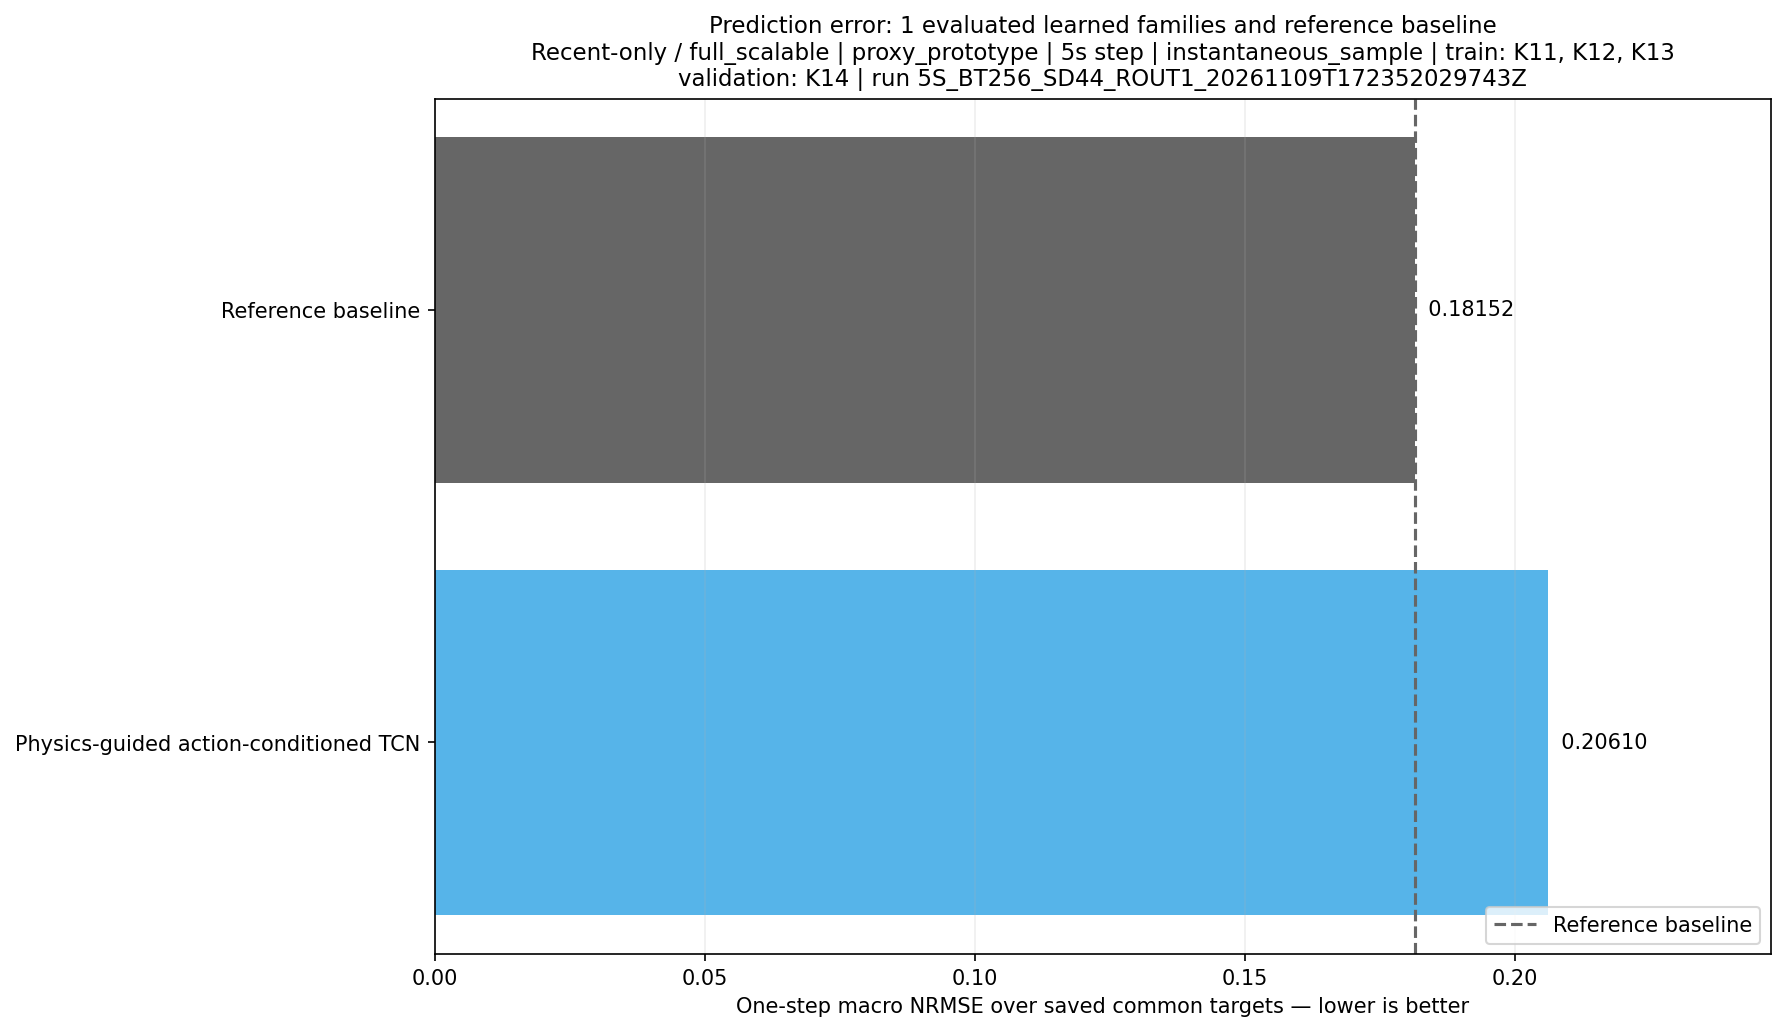

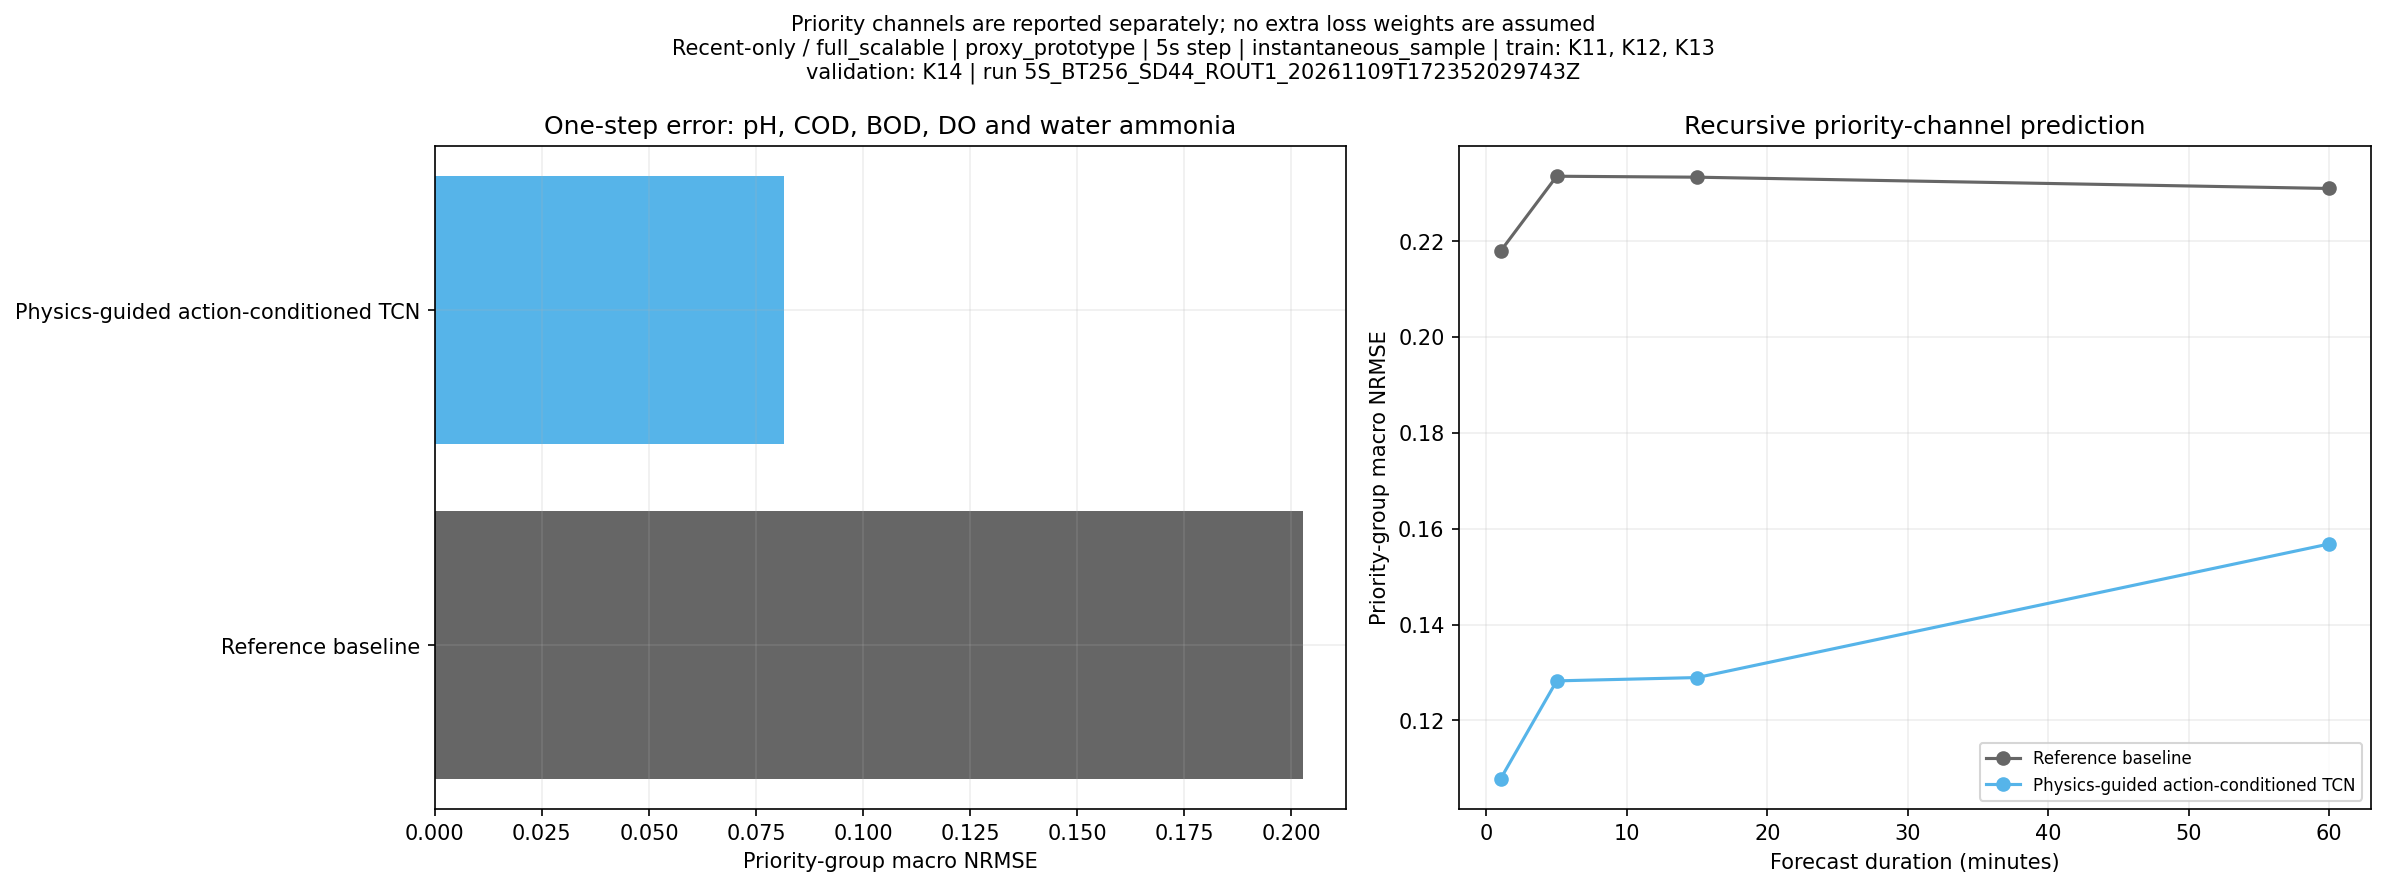

### ***Errors by model and target***

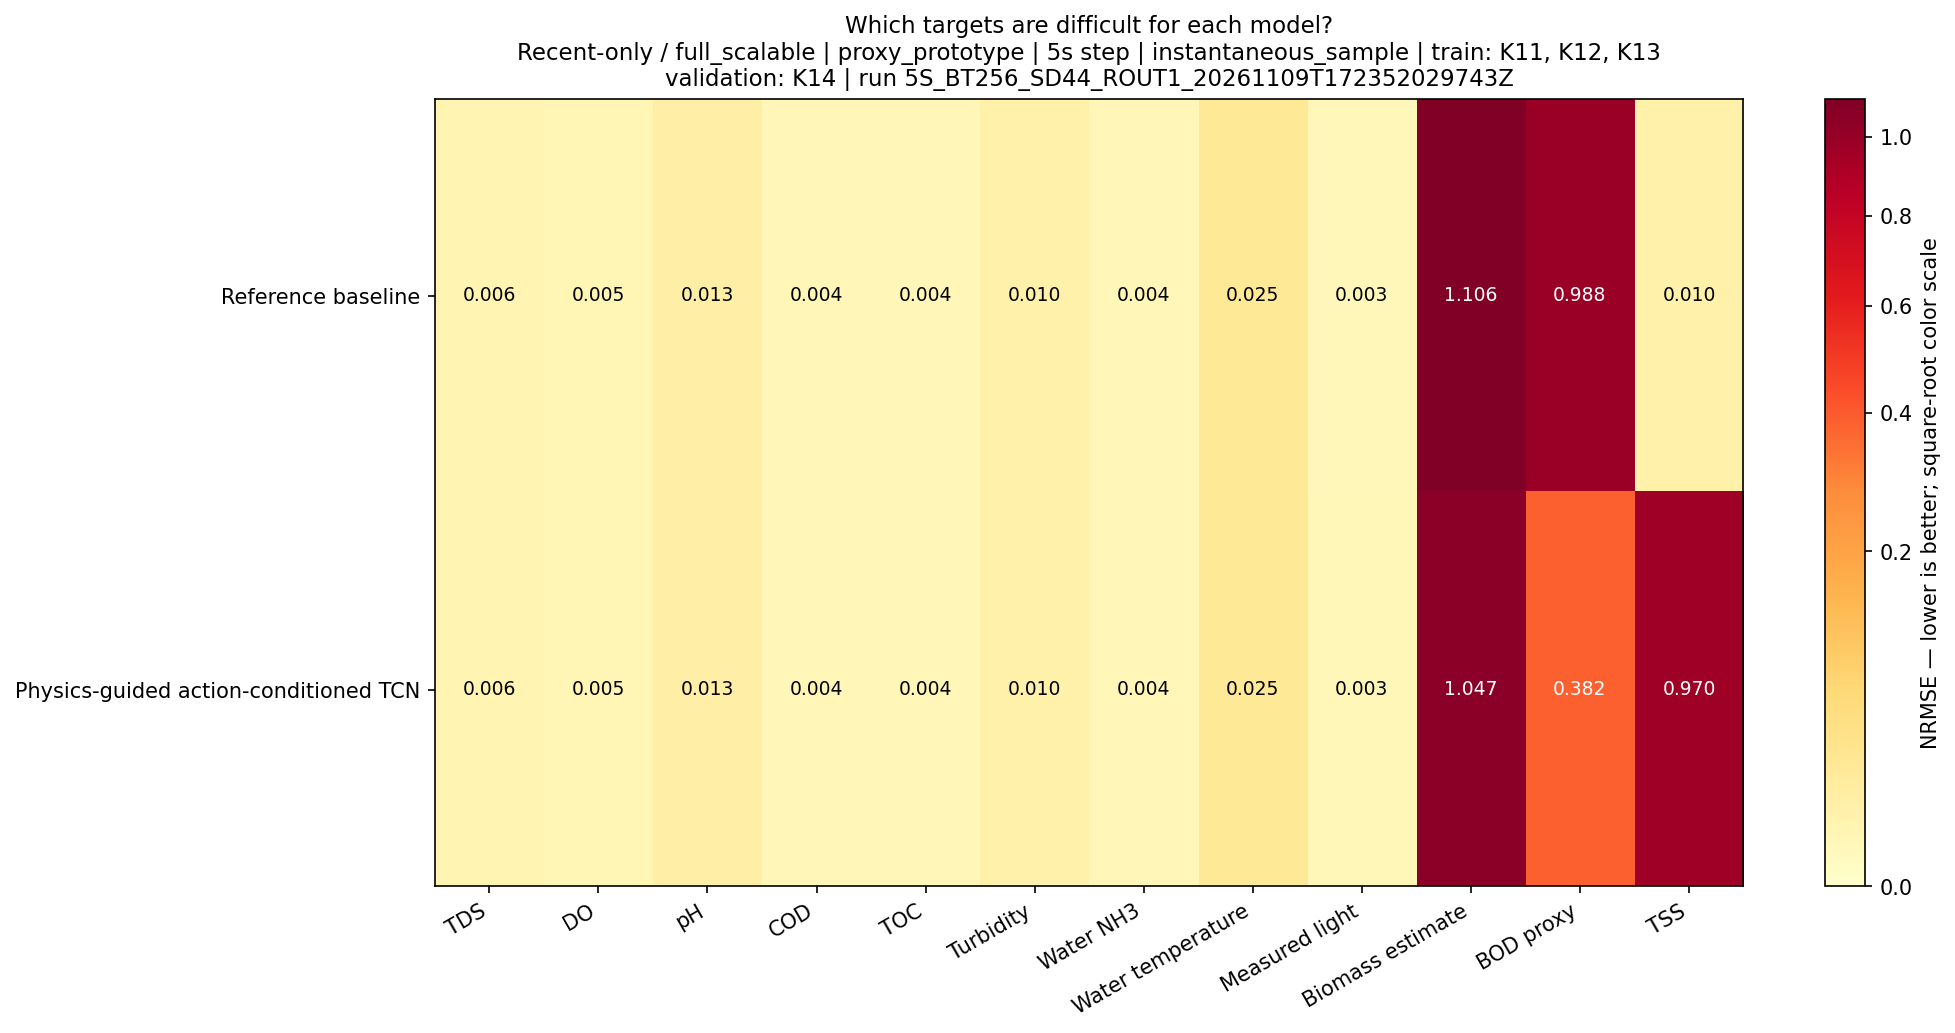

### ***Recursive prediction curves — evaluated families and reference baseline***

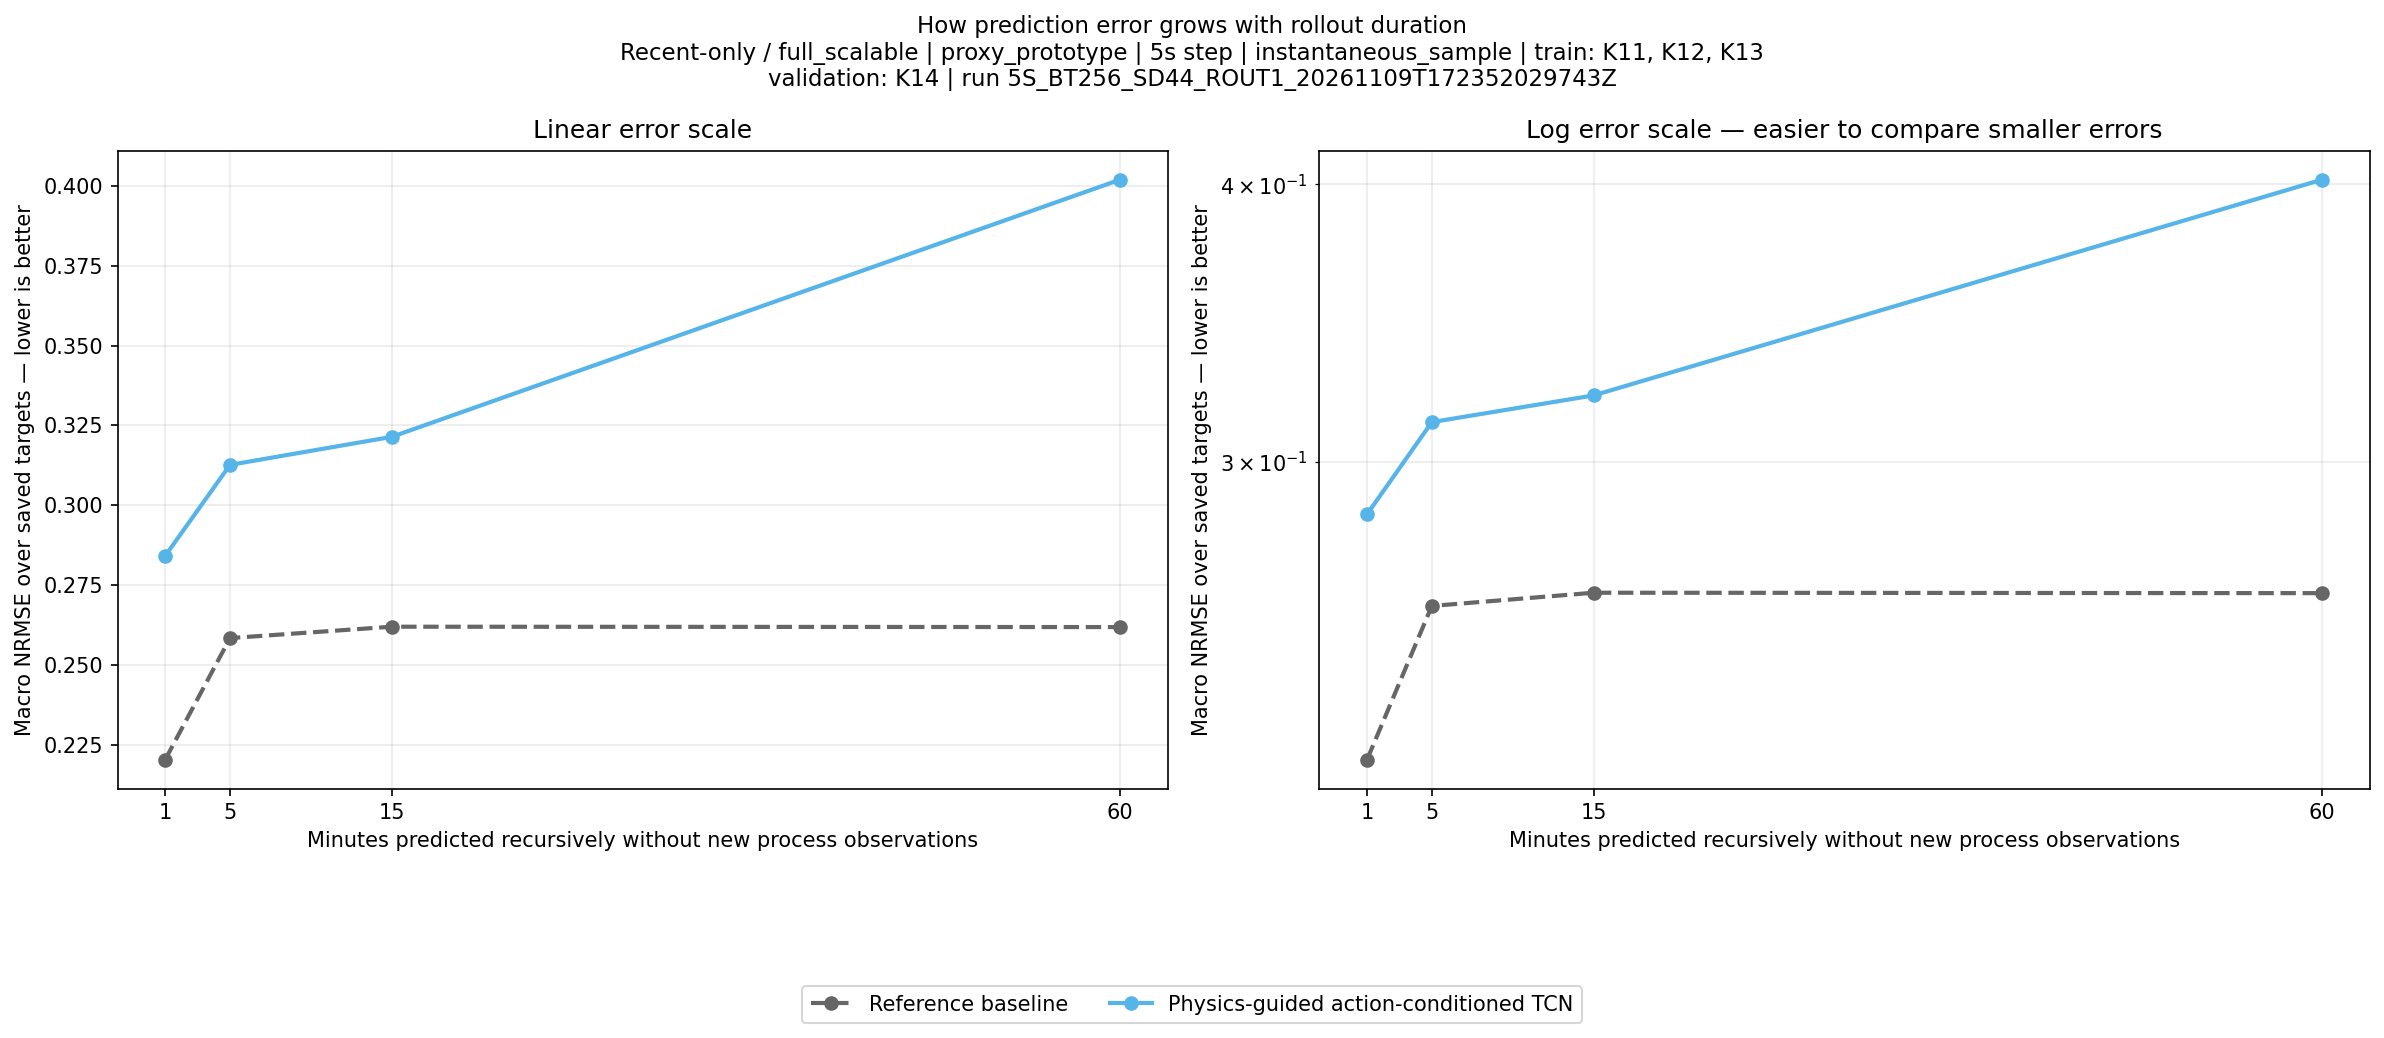

### ***Matched comparison with the physical baseline***

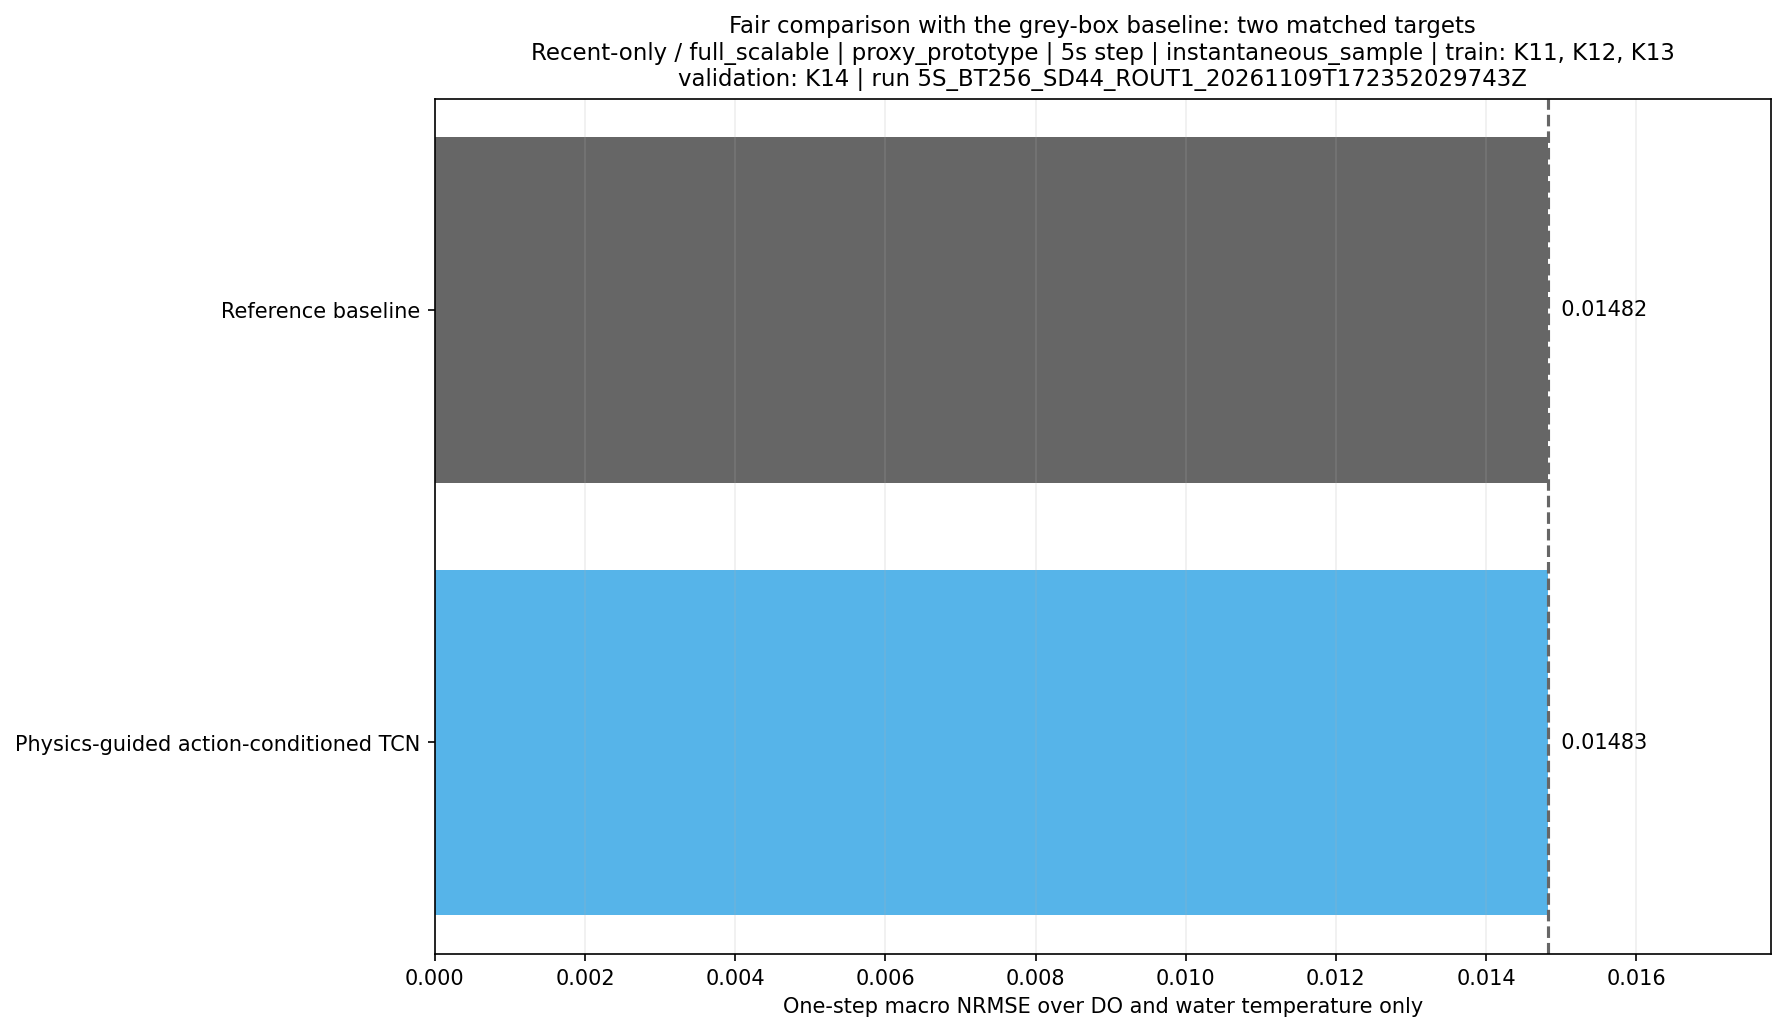

### ***Recorded training and validation curves***

Epoch curves exist for the neural models only. Classical models are compared through prediction-error and rollout curves; no epoch-loss curves are fabricated. MLP ensemble members are shown individually.

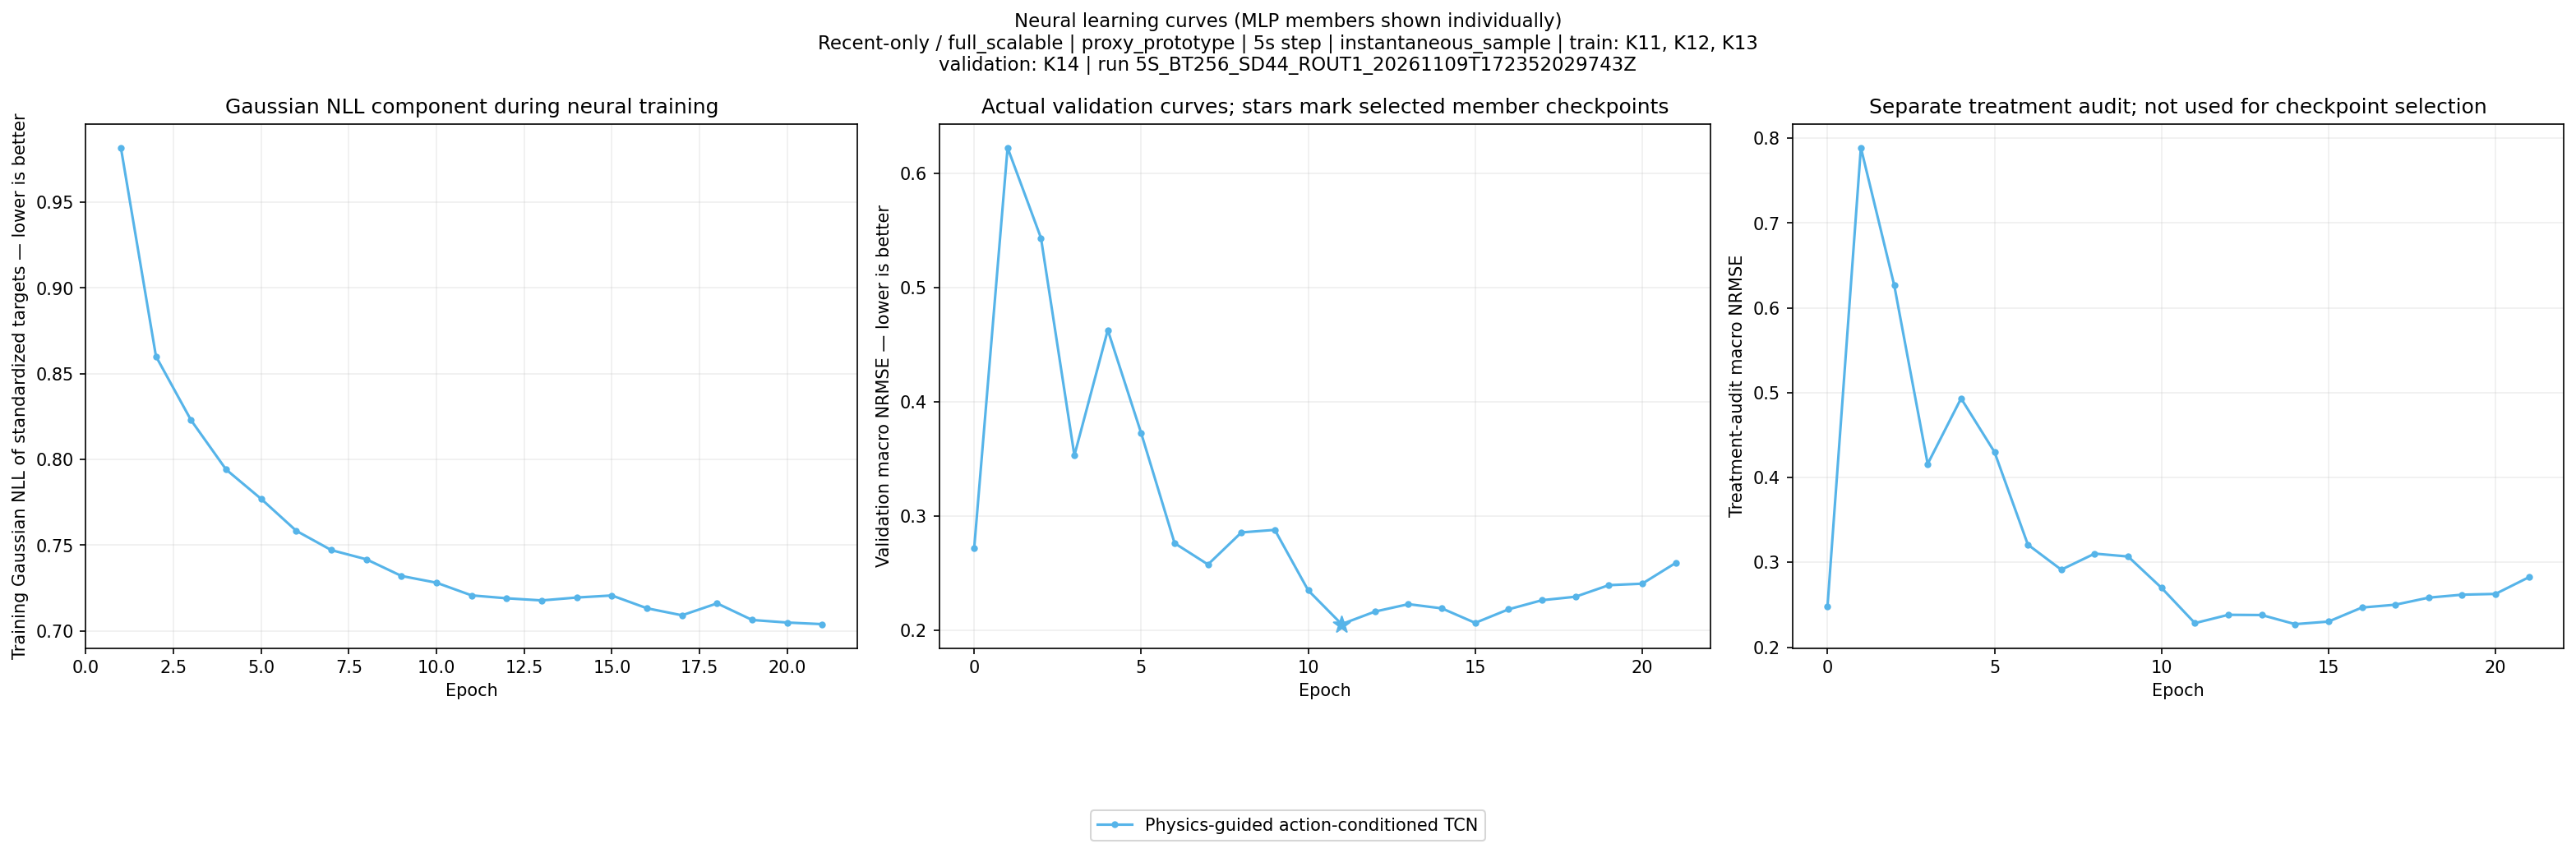

### ***Training time and inference speed***

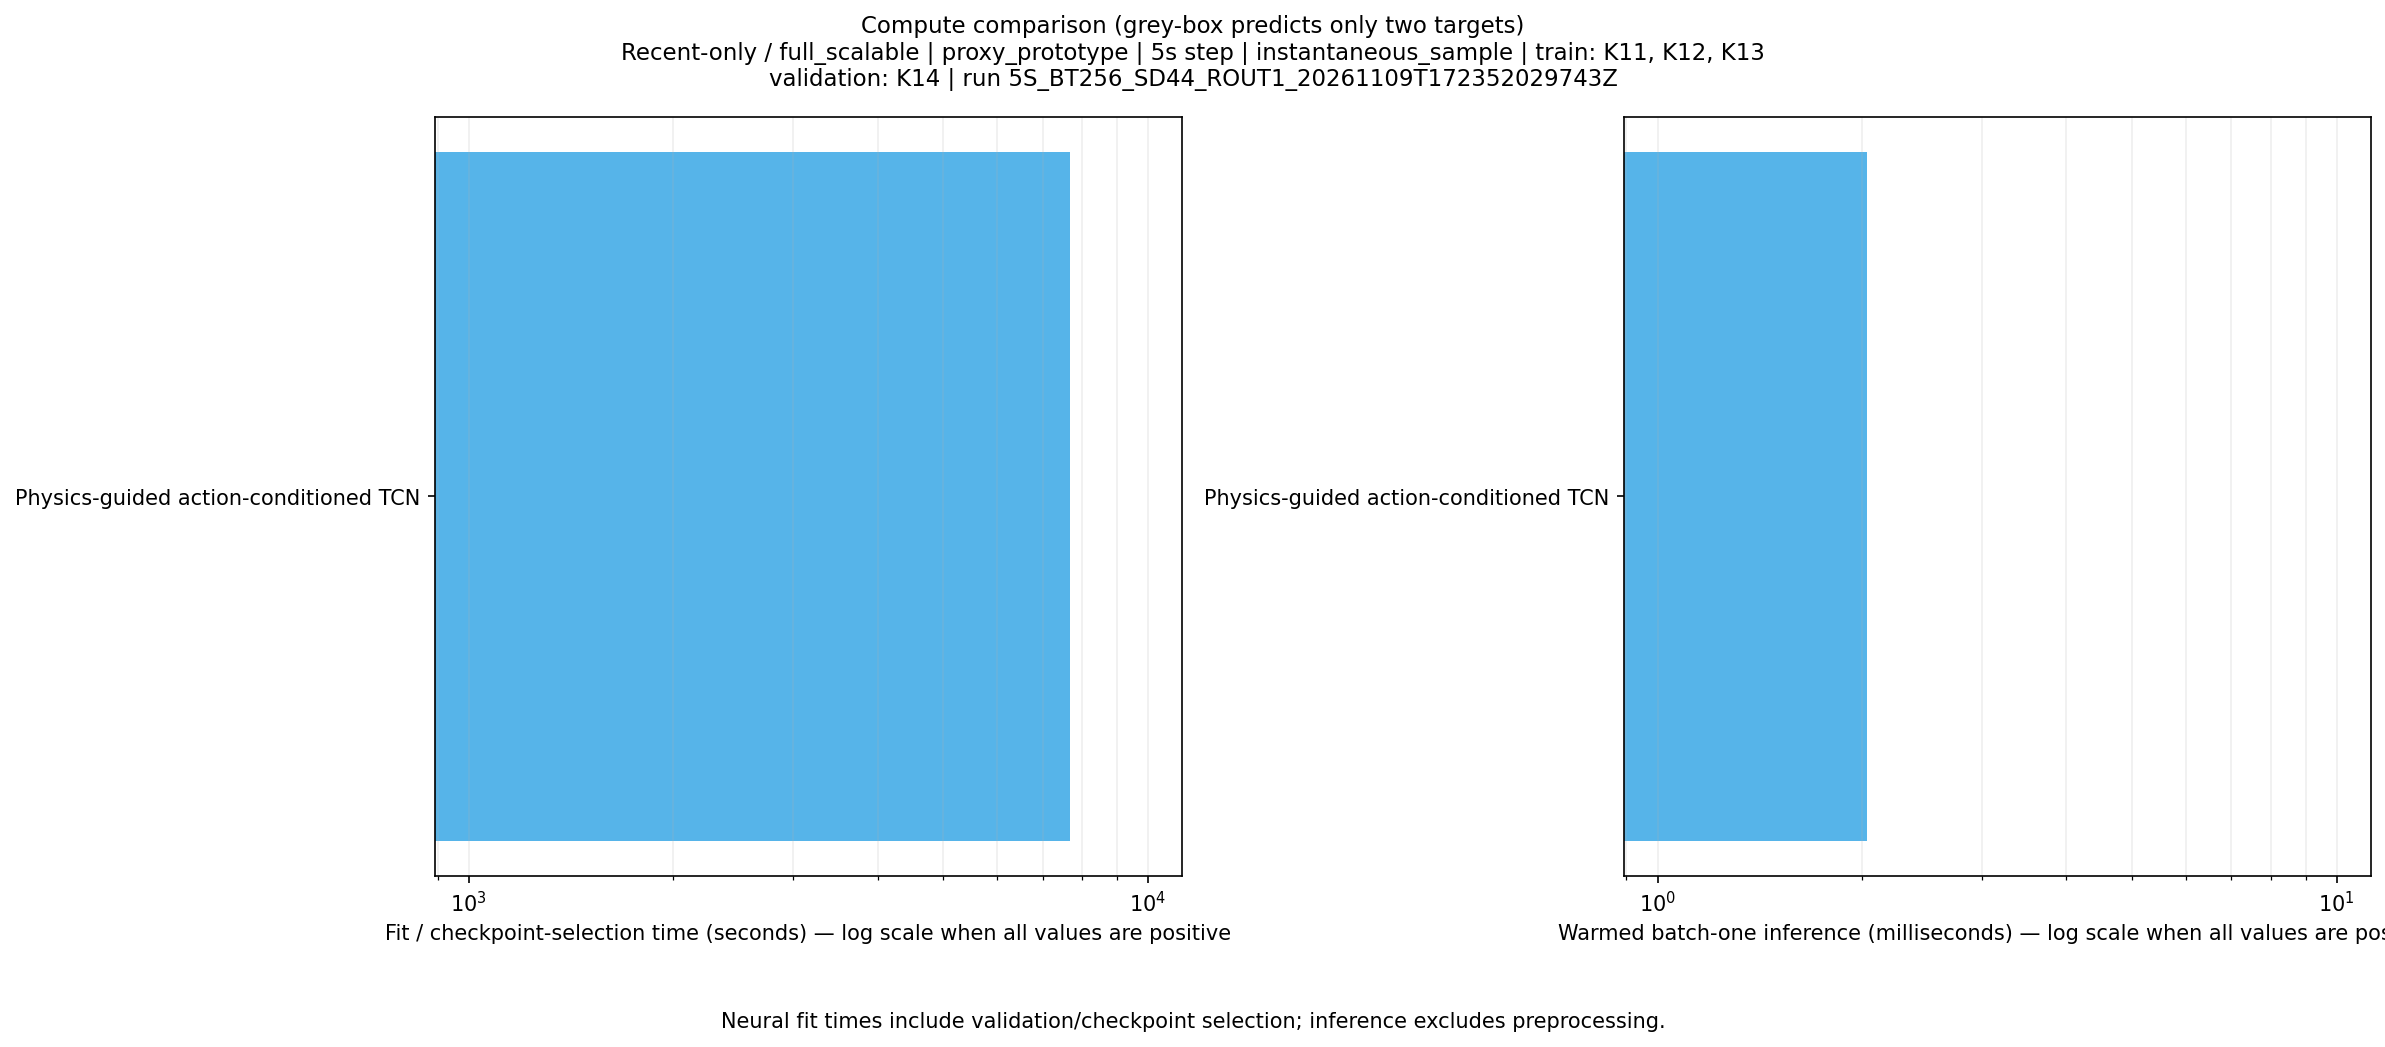

### ***Prediction-interval coverage***

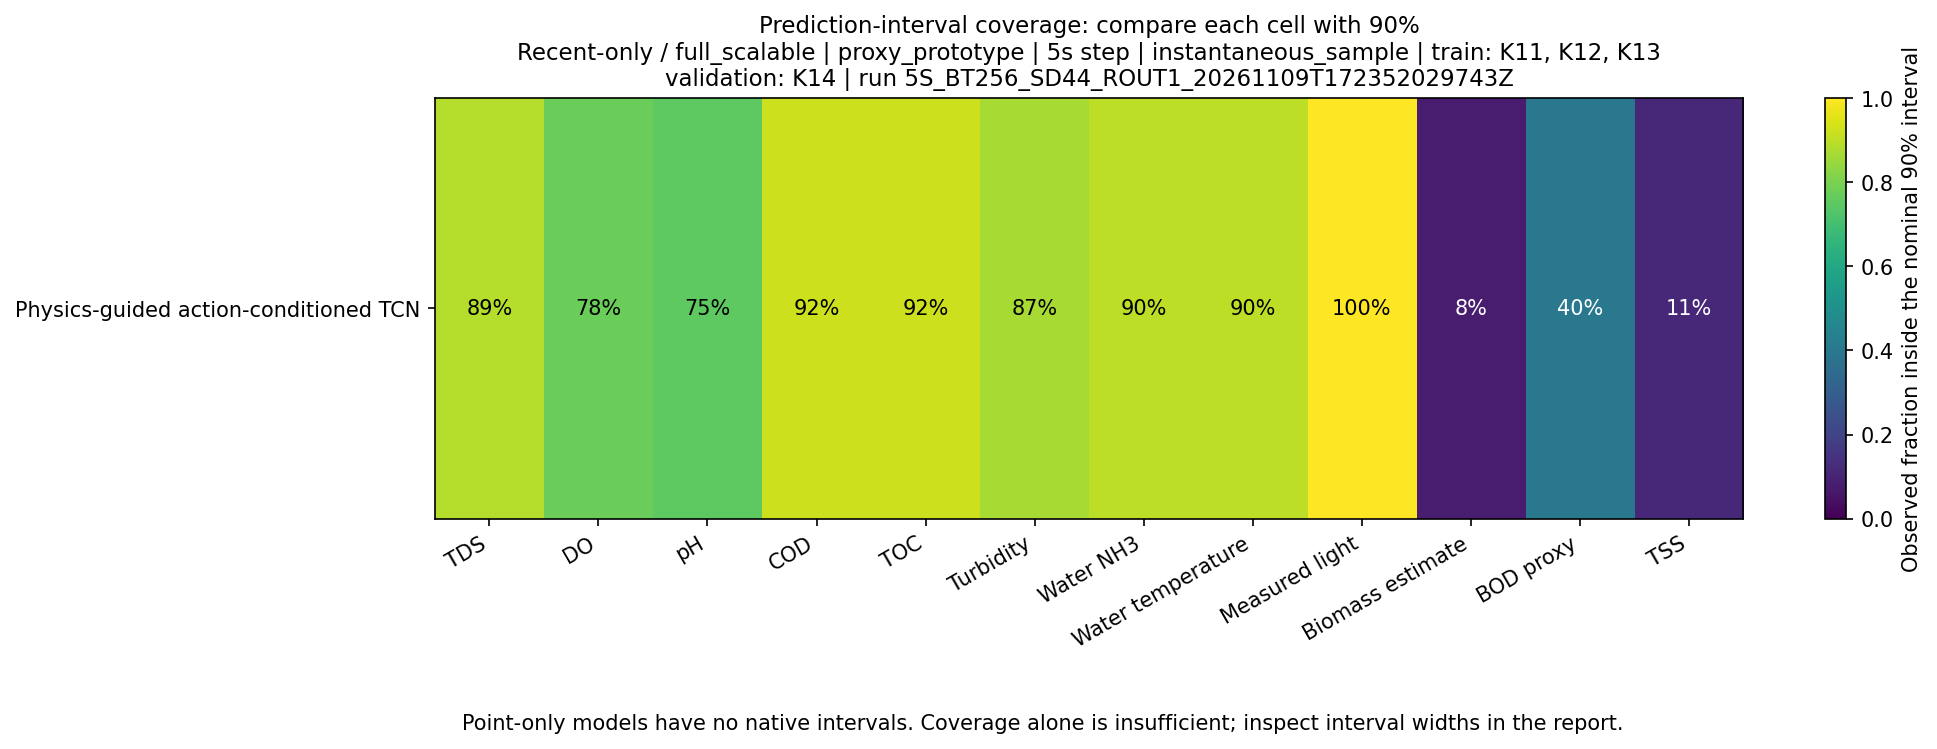

### ***Actual versus predicted sensor values***

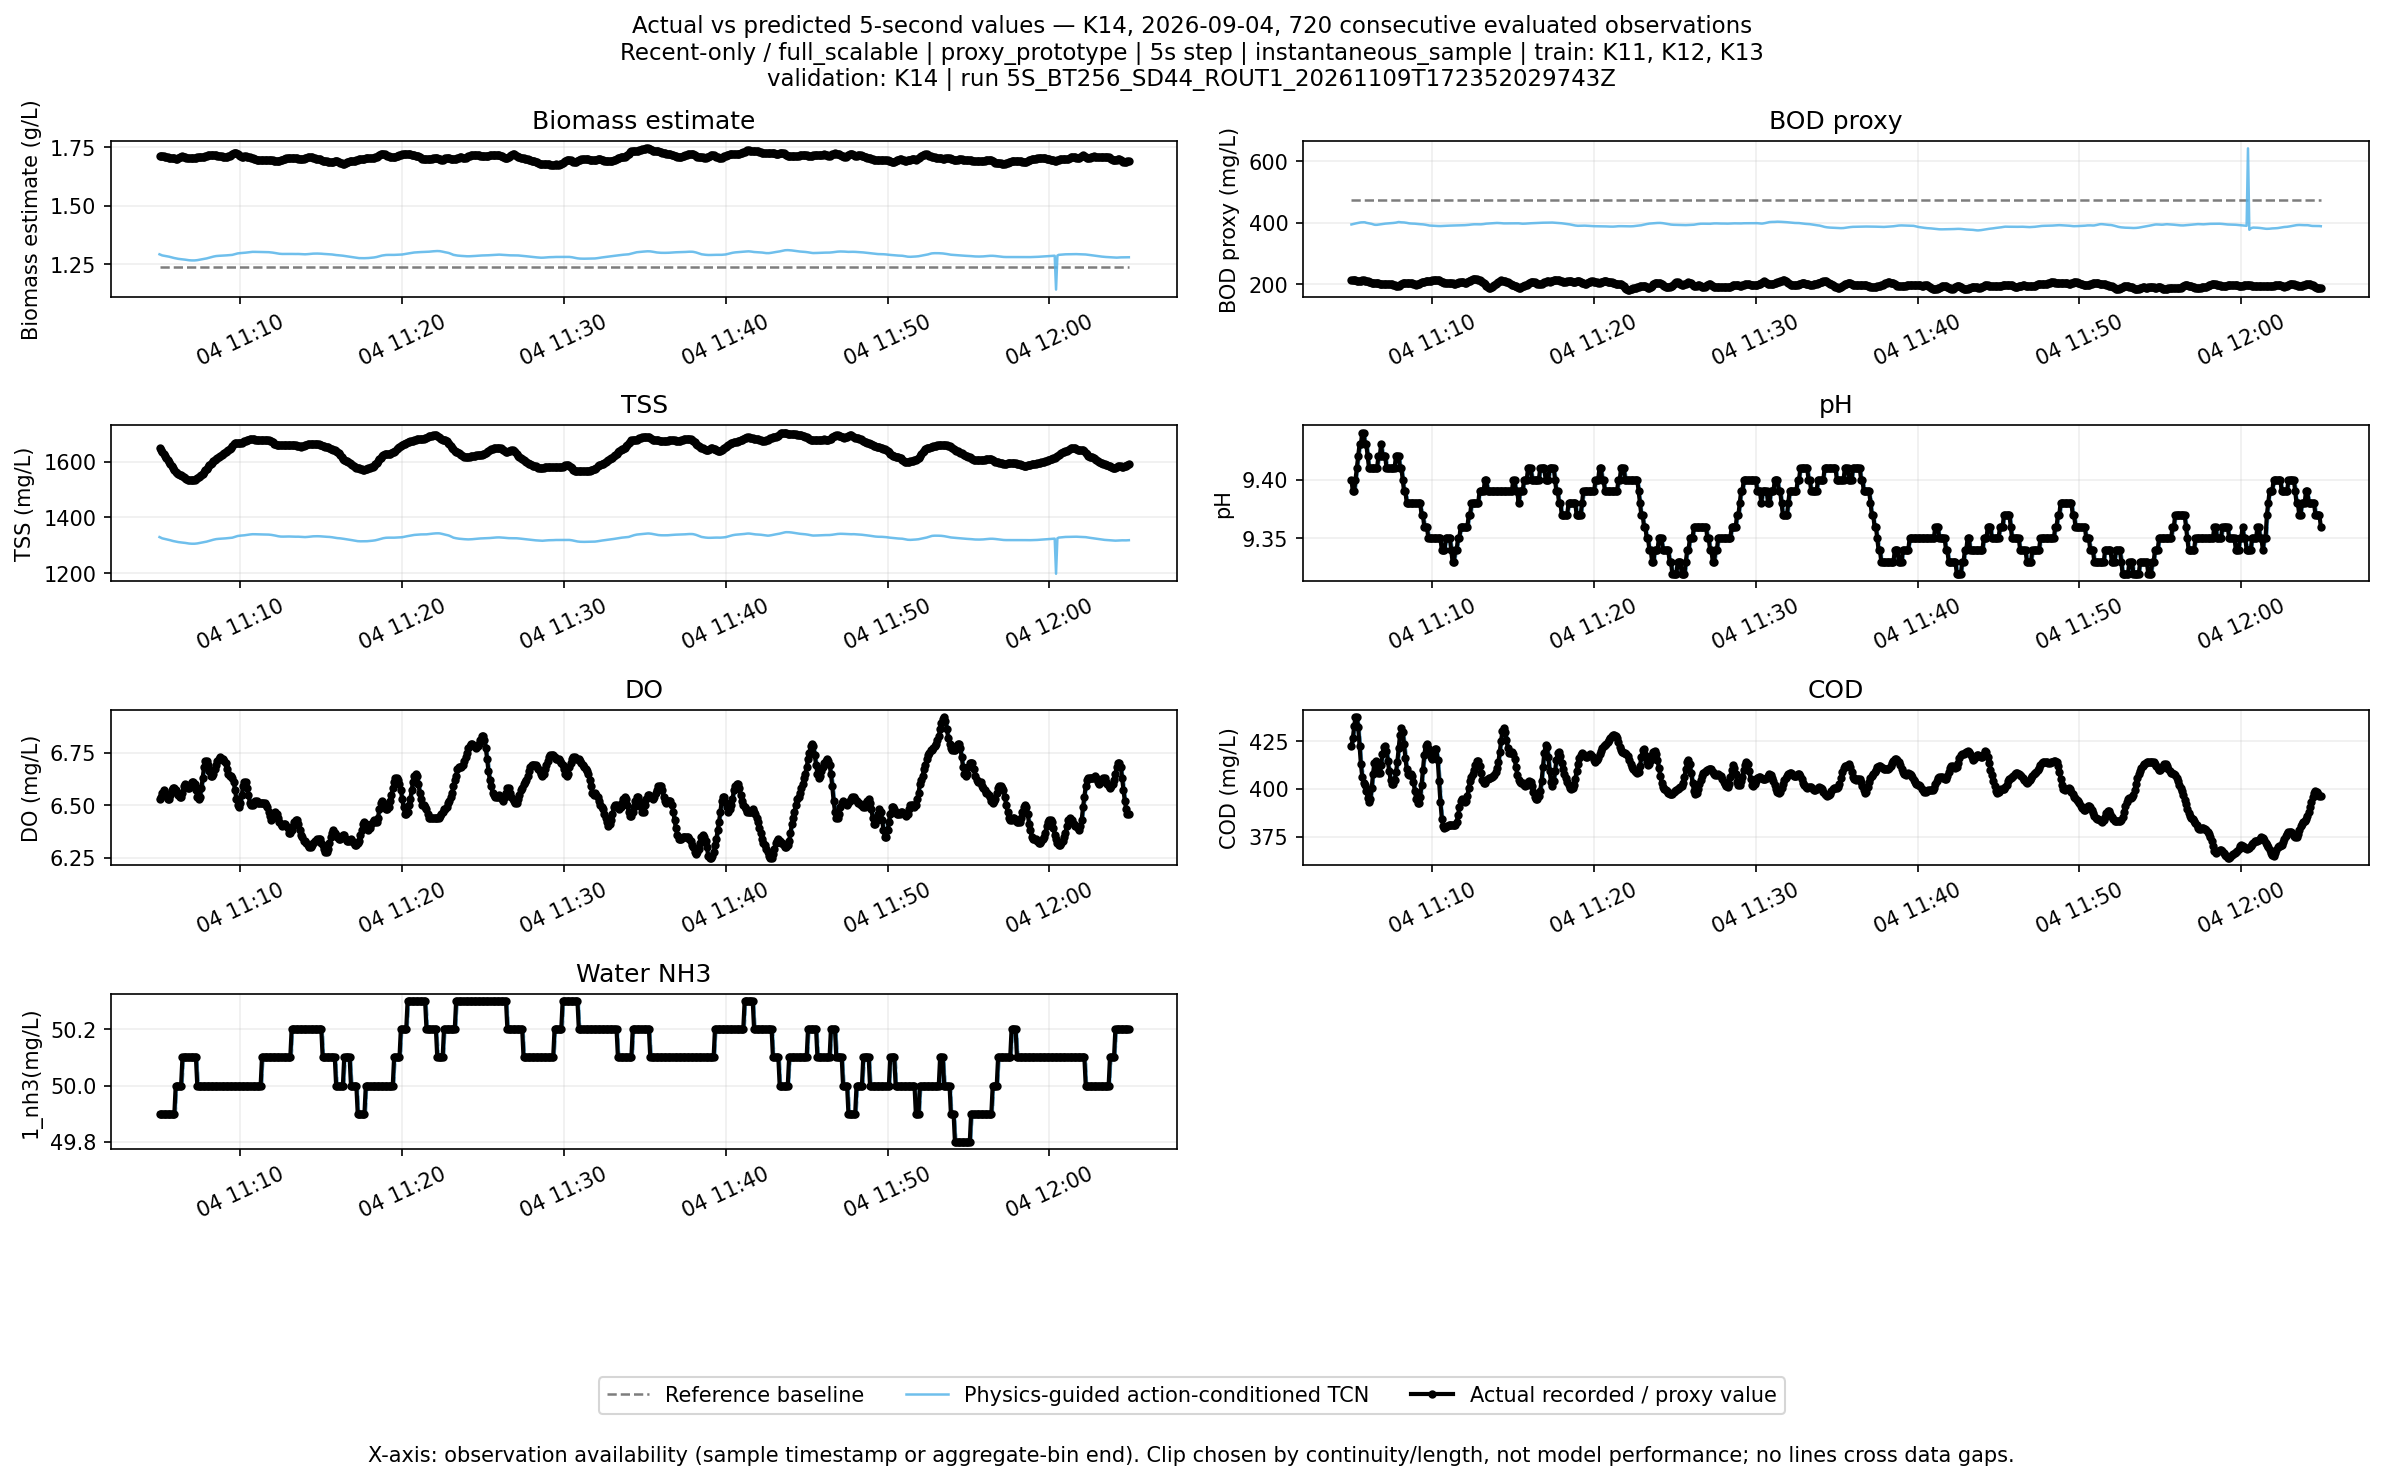

Saved PNG figures: /home/rahmadbisma/Documents/ITS/MBRL_MicroAlgae/dev/world_model/model/5S_BT256_SD44_ROUT1_20261109T172352029743Z/figures/validation
Recursive models replay logged actions and persist unpredicted sensor/context channels; only predicted input channels are fed back.
Biomass/BOD/TSS scores describe supplied proxy columns, not independent biological/treatment validation, when label_mode=proxy_prototype.
Native-unit MAE/RMSE and interval widths are compared per target, not averaged across incompatible units.
Point intervals are one-step marginal intervals; recursive uncertainty coverage is not claimed.
Latency excludes preprocessing; neural fitting time includes checkpoint validation.
Single-seed sampled-window validation does not establish biological replicate or controller generalization.
Saved: evaluation_wm_12targets_proxy_5S_BT256_SD44_ROUT1_20261109T172352029743Z_validation_summary.csv
Saved: evaluation_wm_12targets_proxy_5S_BT256_SD44_ROUT1_20261109T172352029743Z_va

In [6]:
performance_summary, physical_summary, horizon_summary, comparison_all_metrics = build_comparison_reports(
    summary, point_report, rollout_report, uncertainty_report, raw)
display(Markdown('#### ***All-model one-step summary — saved shared targets***'))
display(performance_summary.loc[performance_summary.category.ne('physical')].sort_values('macro_NRMSE', na_position='last'))
display(Markdown('#### ***Five-priority-channel summary***'))
display(priority_point_report)
display(Markdown('#### ***Quality and treatment groups within the broad cohort***'))
display(quality_group_report)
display(Markdown('#### ***Separate dose/quality-event audit; not the overall score***'))
display(event_audit_report)
display(Markdown('#### ***Matched physical-baseline comparison — DO and water temperature***'))
display(physical_summary.sort_values('two_target_macro_NRMSE'))
display(Markdown('#### ***Recursive comparison — every model and evaluated horizon***'))
display(horizon_summary.sort_values(['horizon_minutes', 'macro_NRMSE']) if not horizon_summary.empty else horizon_summary)
display(Markdown('#### ***All native-unit point metrics and uncertainty metrics by target***'))
columns = ['MAE', 'RMSE', 'NRMSE', 'baseline_skill', 'marginal_NLL_native_units',
           'coverage_90pct', 'mean_interval_width_native_units']
point_comparison = comparison_all_metrics.loc[comparison_all_metrics.evaluation_mode.eq('one_step_conditional')]
display(point_comparison.set_index(['target', 'algorithm'])[columns].sort_index())
draw_comparison_figures(summary, point_report, rollout_report, uncertainty_report, trace_raw, predictions_by_model)
print('Recursive models replay logged actions and persist unpredicted sensor/context channels; only predicted input channels are fed back.')
print('Biomass/BOD/TSS scores describe supplied proxy columns, not independent biological/treatment validation, when label_mode=proxy_prototype.')
print('Native-unit MAE/RMSE and interval widths are compared per target, not averaged across incompatible units.')
print('Point intervals are one-step marginal intervals; recursive uncertainty coverage is not claimed.')
print('Latency excludes preprocessing; neural fitting time includes checkpoint validation.')
print('Single-seed sampled-window validation does not establish biological replicate or controller generalization.')

if EVAL_CONFIG['export_reports']:
    report_stem = f"evaluation_{EVAL_CONFIG['prefix']}_{EVAL_CONFIG['run_id']}_{EVAL_CONFIG['split']}"
    exports = {
        'summary': performance_summary,
        'all_metrics': comparison_all_metrics,
        'physical_comparison': physical_summary,
        'horizon_comparison': horizon_summary,
        'point_metrics': point_report,
        'recursive_metrics': rollout_report,
        'uncertainty': uncertainty_report,
        'priority_point': priority_point_report,
        'quality_groups': quality_group_report,
        'event_audit': event_audit_report,
        'checkpoint_coverage': checkpoint_counts, 'assessment_coverage': counts,
        'event_coverage': event_counts, 'rollout_coverage': rollout_coverage,
        'assessment_anchors': pd.DataFrame(raw['anchors']),
        'rollout_anchors': pd.DataFrame(rollout_anchors),
        'trace_anchors': pd.DataFrame(trace_raw['anchors']), 'trace_coverage': trace_counts,
    }
    for name, table in exports.items():
        destination = RUN_DIR / (report_stem + '_' + name + '.csv')
        table = table.assign(input_filter_recipe=json.dumps(preprocessing.get('input_filter', {'mode': 'none'}), sort_keys=True),
                             run_id=EVAL_CONFIG['run_id'], evaluation_split=EVAL_CONFIG['split'],
                             sampling_interval_seconds=SAVED_INTERVAL_SECONDS,
                             observation_operator=reference.get('observation_operator', 'interval_mean'),
                             history_minutes=reference['config']['history_minutes'])
        table.to_csv(destination, index=False)
        print('Saved:', destination.name)
    print('Main comprehensive comparison CSV:', report_stem + '_all_metrics.csv')

    assessment_manifest = {'run_id': EVAL_CONFIG['run_id'], 'evaluation_split': EVAL_CONFIG['split'],
                           'evaluation_settings': EVAL_CONFIG, 'source_manifest': evaluated_sources.to_dict('records'),
                           'model_metadata': [p.name for p in metadata_paths],
                           'sampling_interval_seconds': SAVED_INTERVAL_SECONDS,
                           'observation_operator': reference['observation_operator'],
                           'input_filter': preprocessing.get('input_filter', {'mode': 'none'}),
                           'priority_targets': PRIORITY_TARGETS,
                           'cohorts': {'primary': 'broad temporal sample; no target-based selection',
                                       'events': 'separate enriched audit; never blended into primary score',
                                       'recursive': 'independent starts spanning full eligible episode'},
                           'quality_settings': QUALITY_SETTINGS}
    (RUN_DIR / (report_stem + '_manifest.json')).write_text(json.dumps(assessment_manifest, indent=2, default=str))
